# Clasificación automática de quejas financieras de consumidores

**Curso**: Aprendizaje Supervisado
**Proyecto**: Proyecto final
**Autor**: Jorge Cunalata

**Pipeline:** Texto → limpieza + lematización + stop words → Bag of Words TF‑IDF → Regresión Logística / Naive Bayes Multinomial
**Dataset:** CFPB Consumer Complaint Database [1]

---

## Tabla de contenido

0. [Configuración del entorno](#0)
1. [Introducción y motivación](#1)
2. [Obtención de datos](#2)
3. [Exploratory Data Analysis (EDA)](#3)
4. [Preprocesamiento de texto (lematización y stop words) + Word cloud y palabras frecuentes](#4)
5. [Pipelines de sklearn](#5)
6. [Optimización de hiperparámetros con *repeated k‑fold CV* (curva de λ) + Optuna (extra)](#6)
7. [Curva de aprendizaje](#7)
8. [Comparación estadística: Regresión Logística vs Naive Bayes](#8)
9. [Evaluación final en test](#9)
10. [Visualización con t‑SNE](#10)
11. [Conclusiones](#11)
12. [Referencias (IEEE) y anexo de prompts](#12)

## 1. Introducción y motivación <a id='1'></a>

Las entidades financieras y los reguladores reciben diariamente miles de quejas escritas en lenguaje natural. Solo la *Consumer Financial Protection Bureau* (CFPB) de EE. UU. ha recibido millones de quejas desde 2011, y hasta 2025 publicó las narrativas de los consumidores que dieron su consentimiento [1], [25]. Cada queja debe **enrutarse al área correcta** (reportes de crédito, cobranzas, hipotecas, tarjetas de crédito, cuentas bancarias…). Si este enrutamiento se hace manualmente:

* aumenta el tiempo de respuesta al cliente (y el riesgo de incumplir plazos regulatorios);
* se consumen horas de analistas en una tarea repetitiva;
* los errores de enrutamiento generan reprocesos y peor experiencia de cliente.

**Problema:** dado el texto libre de una queja, predecir automáticamente el **producto financiero** al que se refiere (clasificación multiclase de texto).

**Importancia:** un clasificador ligero, interpretable y barato de entrenar (TF‑IDF + modelo lineal) puede desplegarse como primer filtro de *triage* en un banco, una cámara de compensación o un regulador, priorizando la atención y generando métricas de calidad del servicio por producto. Además, el análisis temporal de las quejas permite detectar picos (por ejemplo, crisis de reportes de crédito) que son de interés para supervisión.

**Objetivos**
1. Construir un *pipeline* reproducible `Texto → TF‑IDF → Modelo` con `sklearn.pipeline.Pipeline` [2], [22].
2. Optimizar el hiperparámetro de regularización λ (= 1/C) con *repeated stratified k‑fold CV*, analizar sesgo/varianza y **usar el mejor valor encontrado** en los modelos finales.
3. Comparar estadísticamente **Regresión Logística multinomial** (discriminativo) vs **Naive Bayes Multinomial** (generativo) [5], [6] con 10×10 *repeated k‑fold* y pruebas de hipótesis [8]–[11].
4. Visualizar la estructura del espacio TF‑IDF con t‑SNE [12].

> **Nota de diseño:** al ser un problema de texto con representación TF‑IDF **no se realiza selección de características**; la complejidad se controla con regularización (λ en LR, α en NB) y con los umbrales `min_df`/`max_df` del vectorizador.

### *Uso de IA generativa*

Siguiendo la indicación del curso, el código de este notebook se desarrolló con apoyo de un asistente de IA generativa. Los *prompts* utilizados, organizados por sección, se encuentran en el **Anexo** al final del notebook.

## 0. Configuración del entorno <a id='0'></a>

### *Dependencias adicionales*

Colab ya incluye pandas, numpy, scikit-learn, scipy, statsmodels, matplotlib y seaborn. El siguiente código instala solo lo que falta:

- `wordcloud`: nubes de palabras (sección 4.1).
- `optuna`: optimización bayesiana de hiperparámetros (sección 6.2, extra).
- `spacy` y el modelo `en_core_web_sm`: lematización y lista de *stop words* en inglés (sección 4).
- `pyarrow`: lectura y escritura de archivos `parquet` (caché de datos).

In [17]:
# ===== Instalación de dependencias (solo si no están disponibles) =====
import sys, subprocess, importlib.util

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

for mod, pkg in [("wordcloud", "wordcloud"), ("optuna", "optuna"), ("spacy", "spacy"), ("pyarrow", "pyarrow")]:
    if importlib.util.find_spec(mod) is None:
        _pip(pkg)
if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"], check=False)

### *Librerías*

Importamos las bibliotecas y módulos que se usan a lo largo del notebook:

- `os`, `re`, `time`, `textwrap`, `warnings`, `zipfile`, `urllib.request`: utilidades de Python para rutas de archivos, expresiones regulares (limpieza de texto), medición de tiempos, formateo de texto, control de advertencias y descarga del dataset.
- `numpy as np` y `pandas as pd` [20]: cálculo numérico y manipulación de datos tabulares.
- `matplotlib.pyplot as plt` [18] y `seaborn as sns`: gráficos.
- `scipy.stats` [19]: asimetría (*skewness*) y pruebas de hipótesis (Wilcoxon, t‑test).
- `joblib.Memory`: caché del paso TF‑IDF dentro del `Pipeline`, para no recalcularlo cuando solo cambia el hiperparámetro del clasificador.
- `sklearn.pipeline.Pipeline`: encadena `TF‑IDF → clasificador` para que todo lo que aprende de los datos se ajuste solo con el *fold* de entrenamiento.
- `TfidfVectorizer` y `CountVectorizer`: representación *Bag of Words* (TF‑IDF y conteos).
- `LogisticRegression` y `MultinomialNB`: los dos modelos que se comparan.
- `train_test_split`, `RepeatedStratifiedKFold`, `GridSearchCV`, `learning_curve`, `cross_validate`: partición de datos, validación cruzada repetida, búsqueda de hiperparámetros y curva de aprendizaje.
- `classification_report`, `confusion_matrix`, `f1_score`, `log_loss`, `silhouette_score`, `ConfusionMatrixDisplay`: métricas de evaluación.
- `TruncatedSVD` y `TSNE`: reducción de dimensionalidad para la visualización t‑SNE.

In [18]:
# importamos librerías
import os, re, sys, time, tempfile, textwrap, warnings, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from joblib import Memory

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     GridSearchCV, learning_curve, cross_validate)
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             log_loss, silhouette_score, ConfusionMatrixDisplay)
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### *Parámetros globales*

El siguiente código define todos los parámetros del experimento en un solo lugar:

- `SEED = 42`: semilla única para el *split*, la validación cruzada, SVD, t‑SNE, Optuna y las nubes de palabras. El generador `rng` se usa solo en t‑SNE (la carga de datos usa su propio generador con la misma semilla), así los resultados son idénticos con o sin caché.
- `N_SAMPLE`: número de quejas que se usan para modelar (15 000, por el costo del 10×10 CV).
- `DATE_MIN`, `DATE_MAX`: periodo de análisis (6 años completos, 2019‑2024).
- `DATASET_DIR`: carpeta **`dataset`** donde se guardan el ZIP descargado y los archivos `parquet` intermedios. El dataset se descarga **una sola vez**; las siguientes corridas lo toman de esta carpeta. En Colab, con `USE_DRIVE = True`, la carpeta se crea en Google Drive (`MyDrive/proyecto_cfpb/dataset`) para que sobreviva al reinicio del entorno (Colab pedirá autorizar el acceso a Drive la primera vez). Con `USE_DRIVE = False` se usa una carpeta `dataset` local, que en Colab se borra al reiniciar el entorno.
- `DATA_URL`, `ZIP_PATH`: origen del dataset y ruta del ZIP dentro de `dataset`.
- `DESIRED_LOSS = 0.30`: desempeño deseado (log‑loss) que se dibuja en la curva de aprendizaje.
- `CV_OPT`: validación cruzada estratificada **5 folds × 2 repeticiones** para optimizar hiperparámetros y para las curvas.
- `CV_CMP`: validación cruzada estratificada **10 folds × 10 repeticiones** para la comparación estadística (5×2 si `FAST_MODE`).
- `CLASS_COLORS`: un color fijo por clase, usado en todos los gráficos.

In [19]:
# ===== Parámetros globales =====
SEED       = 42
FAST_MODE  = bool(int(os.environ.get("FAST_MODE", "0")))  # True -> 2x5 en la comparación (más rápido)
N_SAMPLE   = int(os.environ.get("N_SAMPLE", 15000))       # nº de quejas para modelar
DATE_MIN, DATE_MAX = "2019-01-01", "2025-01-01"           # 6 años completos (2019-2024)
KEEP_FRAC  = float(os.environ.get("CFPB_KEEP_FRAC", 0.05)) # fracción de narrativas que se guardan al leer el CSV
# La descarga oficial actual (files.consumerfinance.gov/ccdb/complaints.csv.zip) ya NO incluye las narrativas:
# se usa la copia del archivo oficial del 31-may-2025 guardada en Internet Archive (fija -> reproducible).
DATA_URL   = os.environ.get("CFPB_URL", "https://web.archive.org/web/20250531184504id_/"
                            "https://files.consumerfinance.gov/ccdb/complaints.csv.zip")

# carpeta "dataset": el ZIP se descarga una sola vez y las siguientes corridas lo reutilizan
IN_COLAB  = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ   # navegador o extensión de VS Code
USE_DRIVE = IN_COLAB   # en Colab: dataset en Google Drive para que persista entre sesiones
DATASET_DIR = os.environ.get("DATASET_DIR", "dataset")
if USE_DRIVE and "DATASET_DIR" not in os.environ:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DATASET_DIR = "/content/drive/MyDrive/proyecto_cfpb/dataset"
    except Exception as e:
        print("No se pudo montar Google Drive; se usa la carpeta local 'dataset':", e)
os.makedirs(DATASET_DIR, exist_ok=True)
ZIP_PATH   = os.environ.get("CFPB_ZIP", os.path.join(DATASET_DIR, "complaints.csv.zip"))
DATA_DIR   = os.environ.get("DATA_DIR", DATASET_DIR)   # parquet intermedios (muestra, serie mensual, lemas)
print("Carpeta del dataset:", os.path.abspath(DATASET_DIR))

RUN_OPTUNA = True
OPTUNA_TRIALS = int(os.environ.get("OPTUNA_TRIALS", 12))
DESIRED_LOSS  = 0.30   # objetivo de negocio: log-loss <= 0.30  (e^-0.30 ≈ 0.74 de prob. media a la clase correcta)

# validación: repeated stratified k-fold
CV_OPT = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)          # optimización / curvas
CV_CMP = (RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED) if FAST_MODE
          else RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED))  # comparación estadística

# caché de transformadores del Pipeline: evita recalcular TF-IDF cuando solo cambia C o alpha
# (en disco local: en Google Drive sería muy lento por la cantidad de archivos pequeños)
memory = Memory(location=os.path.join(tempfile.gettempdir(), "cfpb_sk_cache"), verbose=0)
rng = np.random.default_rng(SEED)   # solo para t-SNE

# paleta de clases (inspirada en el ejemplo de t-SNE del curso)
CLASS_COLORS = {"Credit reporting": "#E41A1C", "Debt collection": "#2E8B22", "Mortgage": "#1F3FD6",
                "Credit card": "#17BECF", "Bank account": "#C71FC7"}
print("FAST_MODE =", FAST_MODE, "| CV comparación:", CV_CMP)

No se pudo montar Google Drive; se usa la carpeta local 'dataset': [dfs_ephemeral] Credentials propagation unsuccessful: the server still reports the credentials as unauthorized
Carpeta del dataset: /content/dataset
FAST_MODE = False | CV comparación: RepeatedStratifiedKFold(n_repeats=10, n_splits=10, random_state=42)


## 2. Obtención de datos <a id='2'></a>

Se descarga el archivo masivo oficial de la CFPB [1] (≈ 1.2 GB comprimido, ≈ 5.9 GB descomprimido) y se lee **por bloques** (`chunksize`) directamente desde el ZIP para no saturar la RAM de Colab.

> **Fuente de datos:** desde 2026 la descarga oficial de la CFPB ya no incluye la columna *Consumer complaint narrative*. Por eso se usa la **copia del archivo oficial del 31 de mayo de 2025 preservada en Internet Archive** [25], que conserva las narrativas y cubre completo el periodo 2019‑2024. Al ser un archivo fijo, cualquier persona que ejecute el notebook obtiene **exactamente la misma muestra**. La descarga (~20‑30 min) se reanuda automáticamente si se interrumpe.

**URL de descarga del dataset**

| | URL |
|---|---|
| Archivo que descarga el notebook (`complaints.csv.zip`, 1.17 GB) | https://web.archive.org/web/20250531184504id_/https://files.consumerfinance.gov/ccdb/complaints.csv.zip |
| Página del snapshot en Internet Archive | https://web.archive.org/web/20250531184504/https://files.consumerfinance.gov/ccdb/complaints.csv.zip |
| Página oficial de la base de datos (CFPB) | https://www.consumerfinance.gov/data-research/consumer-complaints/ |
| Descarga oficial actual (**sin narrativas**, no sirve para este proyecto) | https://files.consumerfinance.gov/ccdb/complaints.csv.zip |

El notebook descarga el archivo automáticamente. Si se prefiere descargarlo a mano (por ejemplo, con el navegador), basta con guardarlo como `dataset/complaints.csv.zip` junto al notebook (o en `MyDrive/proyecto_cfpb/dataset/` si se usa Google Drive en Colab) y el notebook lo reutiliza sin volver a descargarlo.

El siguiente código realiza estos pasos:

1. Define `PRODUCT_MAP`, que agrupa los nombres de producto que la CFPB fue cambiando en el tiempo en **5 clases** estables (*Credit reporting*, *Debt collection*, *Mortgage*, *Credit card*, *Bank account*).
2. `has_narrative()` verifica que el ZIP tenga la columna de narrativa, y `download()` descarga el archivo de forma reanudable.
3. `load_cfpb()` lee el CSV por bloques y, en cada bloque, conserva solo las quejas **con narrativa**, de los 5 productos, sin tarjetas *prepaid*, recibidas entre 2019 y 2024.
4. Guarda la serie de **todas** las quejas filtradas (fecha + clase) para el análisis temporal, y una muestra aleatoria del texto (`KEEP_FRAC`) de la que se extraen `N_SAMPLE` quejas para modelar.
5. Guarda el resultado en la carpeta `dataset` en formato `parquet`.

**Reutilización entre corridas.** El código revisa la carpeta `dataset` en este orden:
* si ya existen los `parquet` de la muestra (con el mismo `N_SAMPLE` y `KEEP_FRAC`) y de la serie mensual, los carga directamente (segundos);
* si no, pero el ZIP ya está descargado, lo vuelve a leer **sin descargarlo** (útil para probar otro `N_SAMPLE`);
* solo si el ZIP no existe (o está incompleto), lo descarga.

Los nombres de los `parquet` incluyen `N_SAMPLE` y `KEEP_FRAC`, de modo que cambiar estos parámetros nunca reutiliza por error una muestra anterior.

In [20]:
# ===== Carga del dataset CFPB =====
PRODUCT_MAP = {
    "Credit reporting, credit repair services, or other personal consumer reports": "Credit reporting",
    "Credit reporting or other personal consumer reports": "Credit reporting",
    "Credit reporting": "Credit reporting",
    "Debt collection": "Debt collection",
    "Mortgage": "Mortgage",
    "Credit card or prepaid card": "Credit card",
    "Credit card": "Credit card",
    "Checking or savings account": "Bank account",
    "Bank account or service": "Bank account",
}
SAMPLE_TAG  = f"n{N_SAMPLE}_k{KEEP_FRAC:g}"   # la muestra depende de N_SAMPLE y KEEP_FRAC
SAMPLE_PATH = os.path.join(DATA_DIR, f"cfpb_sample_{SAMPLE_TAG}.parquet")
SERIES_PATH = os.path.join(DATA_DIR, "cfpb_monthly.parquet")

def has_narrative(path):
    try:
        return "Consumer complaint narrative" in pd.read_csv(path, nrows=0, compression="zip").columns
    except Exception:   # no existe, ZIP incompleto o sin la columna
        return False

def download(url, path, retries=30, block=8 << 20):
    """Descarga reanudable (HTTP Range) a <path>.part; tolera cortes de red."""
    tmp = path + ".part"
    for attempt in range(retries):
        done = os.path.getsize(tmp) if os.path.exists(tmp) else 0
        try:
            req = urllib.request.Request(url, headers={"Range": f"bytes={done}-"})
            with urllib.request.urlopen(req, timeout=120) as resp:
                if resp.status != 206:            # el servidor ignoró el Range: se empieza de cero
                    done = 0
                total = done + int(resp.headers.get("Content-Length", 0))
                with open(tmp, "ab" if done else "wb") as f:
                    while chunk := resp.read(block):
                        f.write(chunk); done += len(chunk)
                        print(f"\r  {done / 1e6:,.0f} / {total / 1e6:,.0f} MB", end="")
            if done >= total:
                break
        except urllib.error.HTTPError as e:
            if e.code == 416:                     # el .part ya está completo
                break
            print(f"\n  reintento {attempt + 1}: {e}"); time.sleep(10)
        except Exception as e:
            print(f"\n  reintento {attempt + 1}: {e}"); time.sleep(10)
    os.replace(tmp, path)
    print()

def load_cfpb():
    # ---- 1. muestra y serie ya procesadas en la carpeta dataset ----
    if os.path.exists(SAMPLE_PATH) and os.path.exists(SERIES_PATH):
        print("Cargando muestra y serie desde", DATA_DIR)
        return pd.read_parquet(SAMPLE_PATH), pd.read_parquet(SERIES_PATH)
    # ---- 2. ZIP ya descargado -> se reutiliza; si no, se descarga una sola vez ----
    if has_narrative(ZIP_PATH):
        print("Usando el ZIP ya descargado:", ZIP_PATH)
    else:
        print("Descargando", DATA_URL, "->", ZIP_PATH)
        download(DATA_URL, ZIP_PATH)
        if not has_narrative(ZIP_PATH):
            raise ValueError(f"{ZIP_PATH} no contiene la columna 'Consumer complaint narrative'. "
                             "Descarga un archivo del CFPB con narrativas y apunta CFPB_ZIP a él.")
    # ---- 3. lectura por bloques ----
    cols = ["Date received", "Product", "Sub-product", "Consumer complaint narrative"]
    kept, series = [], []
    rng_load = np.random.default_rng(SEED)   # generador propio: no altera el rng global (t-SNE)
    t0 = time.time()
    for chunk in pd.read_csv(ZIP_PATH, usecols=cols, dtype=str, chunksize=400_000, compression="zip"):
        chunk = chunk.dropna(subset=["Consumer complaint narrative"])
        chunk = chunk[chunk["Product"].isin(PRODUCT_MAP)]
        chunk = chunk[~chunk["Sub-product"].fillna("").str.contains("prepaid", case=False)]
        chunk["date"] = pd.to_datetime(chunk["Date received"], errors="coerce")
        chunk = chunk[(chunk["date"] >= DATE_MIN) & (chunk["date"] < DATE_MAX)].copy()
        chunk["label"] = chunk["Product"].map(PRODUCT_MAP)
        series.append(chunk[["date", "label"]])
        kept.append(chunk[rng_load.random(len(chunk)) < KEEP_FRAC][["date", "label", "Consumer complaint narrative"]])
    pool = pd.concat(kept).rename(columns={"Consumer complaint narrative": "text"})
    ser = pd.concat(series)
    monthly = (ser.groupby([pd.Grouper(key="date", freq="MS"), "label"]).size()
                  .unstack(fill_value=0))
    # muestra aleatoria simple: conserva la distribución real (desbalance) de las clases
    df = pool.sample(n=min(N_SAMPLE, len(pool)), random_state=SEED).reset_index(drop=True)
    df.to_parquet(SAMPLE_PATH); monthly.to_parquet(SERIES_PATH)
    print(f"Leído en {time.time()-t0:.0f}s | población filtrada: {len(ser):,} | pool: {len(pool):,}")
    return df, monthly

df, monthly = load_cfpb()
print(df.shape)
# vemos las primeras 5 filas
df.head()

Descargando https://web.archive.org/web/20250531184504id_/https://files.consumerfinance.gov/ccdb/complaints.csv.zip -> dataset/complaints.csv.zip
  1,173 / 1,173 MB
Leído en 103s | población filtrada: 2,011,276 | pool: 100,137
(15000, 3)


,date,label,text
0,2024-05-23,Credit reporting,I recently reviewed a copy of my credit report...
1,2019-07-22,Credit card,I notified regions bank of multiple fraud char...
2,2022-02-26,Bank account,Bank of America authorized a creditor to offse...
3,2019-05-17,Debt collection,I filed for Chapter XXXX Bankruptcy in XXXX. M...
4,2023-03-12,Credit reporting,"According to the Fair Reporting Credit Act, th..."


### *Detalles de la base de datos*

*	`date` - Fecha en que la CFPB recibió la queja (2019‑2024).
*	`label` - Producto financiero de la queja (variable de salida, 5 clases): *Credit reporting*, *Debt collection*, *Mortgage*, *Credit card*, *Bank account*.
*	`text` - Narrativa escrita por el consumidor (en inglés), con los datos personales anonimizados por la CFPB (`XXXX`, `XX/XX/XXXX`, montos `{$100.00}`).

## ✅ 3. Exploratory Data Analysis (EDA) <a id='3'></a>

El EDA responde las preguntas mínimas del enunciado:

1. ¿La data está balanceada? (3.1)
2. ¿Se necesitan transformaciones no lineales (*skewness*)? (3.2)
3. ¿Está normalizada? (3.3)
4. ¿Hay estacionalidad en la serie de tiempo? (3.4)

Al ser un problema de texto, además se presentan la nube de palabras y las palabras frecuentes después del preprocesamiento (4.1).

### ✅ 3.1 ¿La data está balanceada?

El siguiente código cuenta las quejas por clase (`value_counts`), calcula su porcentaje y el **ratio de desbalance** (clase mayoritaria / clase minoritaria). La figura de la izquierda muestra la muestra de modelado y la de la derecha la proporción de cada producto en toda la población 2019‑2024.

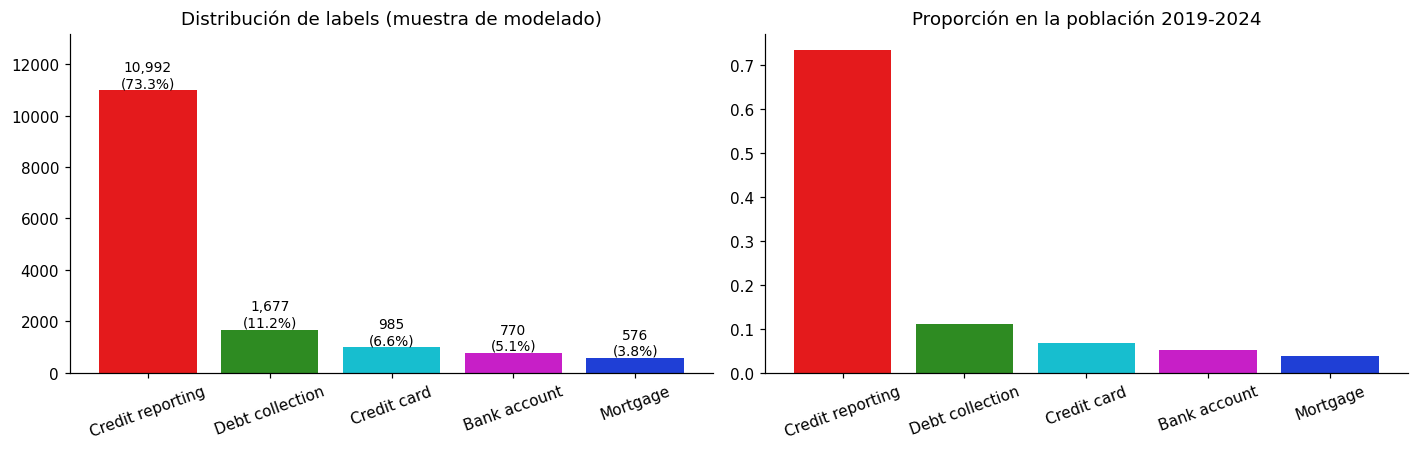

Ratio de desbalance (mayoritaria/minoritaria): 19.1:1


In [21]:
# ===== Distribución de clases =====
counts = df["label"].value_counts()
pct = counts / counts.sum()
imb_ratio = counts.max() / counts.min()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index])
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax[0].text(i, c, f"{c:,}\n({p:.1%})", ha="center", va="bottom", fontsize=9)
ax[0].set_title("Distribución de labels (muestra de modelado)"); ax[0].tick_params(axis="x", rotation=20)
ax[0].set_ylim(0, counts.max() * 1.2)
pop = monthly.sum().sort_values(ascending=False)
ax[1].bar(pop.index, pop.values / pop.sum(), color=[CLASS_COLORS[c] for c in pop.index])
ax[1].set_title("Proporción en la población 2019-2024"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print(f"Ratio de desbalance (mayoritaria/minoritaria): {imb_ratio:.1f}:1")

### 📝 Discusión: balance de clases

La data **no está balanceada**: la clase *Credit reporting* domina claramente (ver ratio impreso). Consecuencias para el diseño:
* se usa **`StratifiedKFold`** (repetido) para que cada fold mantenga las proporciones;
* la métrica principal de comparación es **macro‑F1** (promedia por clase, no premia predecir siempre la mayoritaria); la exactitud se reporta solo como referencia;
* la división train/test también es estratificada.

### ✅ 3.2 Longitud de los textos y asimetría (*skewness*): ¿se necesitan transformaciones no lineales?

El siguiente código calcula el número de palabras de cada queja (`n_words`) y su asimetría (*skewness*) antes y después de aplicar `log1p`. Se grafican:

1. el histograma de la longitud original;
2. el histograma de `log(1 + palabras)`;
3. un *boxplot* de la longitud por clase (sin *outliers*).

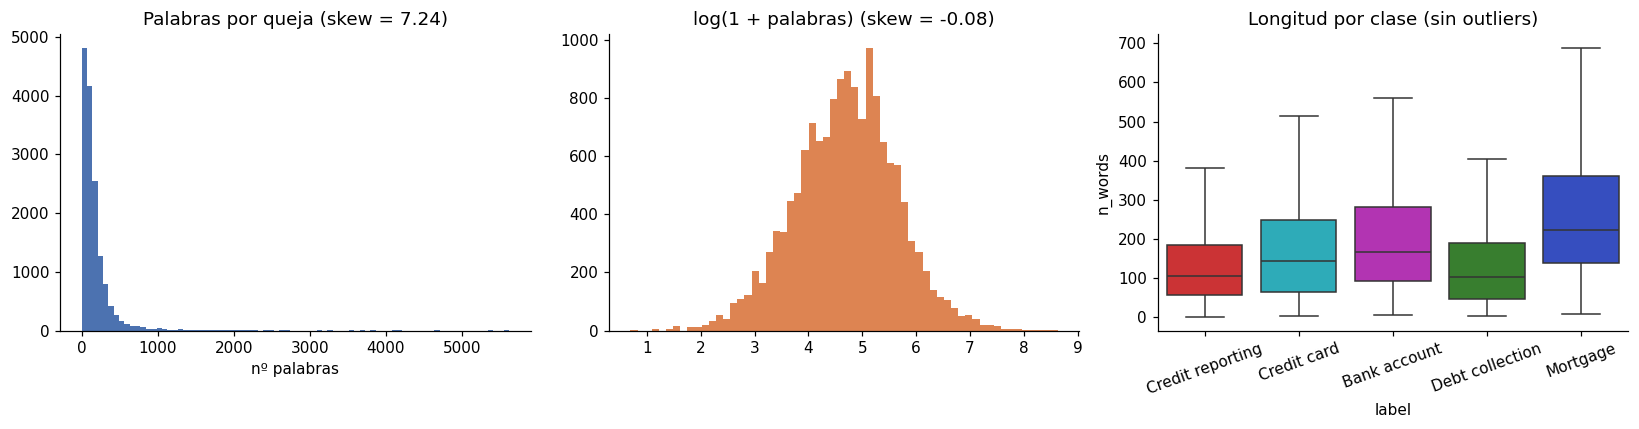

                   mean    50%     max
label                                 
Bank account      237.0  168.0  5370.0
Credit card       200.0  144.0  3582.0
Credit reporting  158.0  105.0  5625.0
Debt collection   158.0  103.0  1854.0
Mortgage          296.0  223.0  2399.0


In [22]:
# ===== Longitud de las quejas y skewness =====
df["n_words"] = df["text"].str.split().str.len()
sk_raw, sk_log = stats.skew(df["n_words"]), stats.skew(np.log1p(df["n_words"]))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df["n_words"], bins=80, color="#4C72B0"); ax[0].set_title(f"Palabras por queja (skew = {sk_raw:.2f})")
ax[0].set_xlabel("nº palabras")
ax[1].hist(np.log1p(df["n_words"]), bins=60, color="#DD8452"); ax[1].set_title(f"log(1 + palabras) (skew = {sk_log:.2f})")
sns.boxplot(data=df, x="label", y="n_words", ax=ax[2], palette=CLASS_COLORS, showfliers=False)
ax[2].tick_params(axis="x", rotation=20); ax[2].set_title("Longitud por clase (sin outliers)")
plt.tight_layout(); plt.show()
print(df.groupby("label")["n_words"].describe()[["mean", "50%", "max"]].round(0))

### 📝 Discusión: asimetría

La longitud de las quejas tiene una **asimetría positiva fuerte** (cola larga a la derecha); `log1p` la reduce notablemente. Para el modelo esto se traduce en dos decisiones:
1. **`sublinear_tf=True`** en `TfidfVectorizer`: reemplaza la frecuencia de término *tf* por `1 + log(tf)` [3], [4], es decir, una **transformación no lineal logarítmica** que evita que textos largos con palabras repetidas dominen.
2. La **normalización L2** por documento (siguiente sección) elimina el efecto de la longitud.

La distribución de frecuencias de palabras (ley de Zipf [24]) también es extremadamente asimétrica, como se ve a continuación; el factor **IDF** (log) compensa que las palabras muy comunes dominen.

### ✅ 3.3 ¿Está normalizada?

En texto, "normalizar" se refiere a la escala de los vectores de cada documento. El siguiente código toma 3 000 quejas, las vectoriza con *Bag of Words* (conteos, `CountVectorizer`) y con TF‑IDF (`TfidfVectorizer`), y compara la **norma L2** de los vectores en ambos casos. El tercer gráfico muestra la ley de Zipf (rango vs frecuencia en escala log‑log).

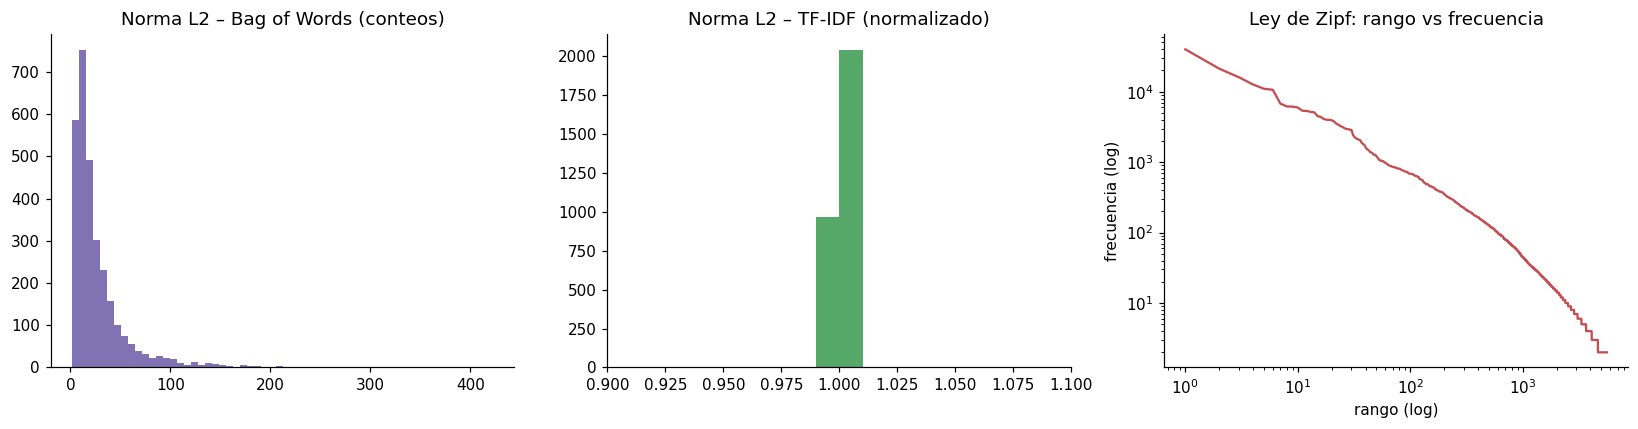

BoW: norma media=27.8, std=32.9 | TF-IDF: norma media=1.000, std=0.000


In [23]:
# ===== Normas L2: Bag of Words vs TF-IDF =====
_sub = df["text"].sample(3000, random_state=SEED)
Xc = CountVectorizer(min_df=2).fit_transform(_sub)
Xt = TfidfVectorizer(min_df=2, sublinear_tf=True).fit_transform(_sub)
norm_c = np.sqrt(Xc.multiply(Xc).sum(1)).A1
norm_t = np.sqrt(Xt.multiply(Xt).sum(1)).A1
freqs = np.sort(Xc.sum(0).A1)[::-1]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(norm_c, bins=60, color="#8172B3"); ax[0].set_title("Norma L2 – Bag of Words (conteos)")
ax[1].hist(norm_t, bins=20, range=(0.9, 1.1), color="#55A868"); ax[1].set_title("Norma L2 – TF-IDF (normalizado)")
ax[1].set_xlim(0.9, 1.1)
ax[2].loglog(np.arange(1, len(freqs) + 1), freqs, color="#C44E52"); ax[2].set_title("Ley de Zipf: rango vs frecuencia")
ax[2].set_xlabel("rango (log)"); ax[2].set_ylabel("frecuencia (log)")
plt.tight_layout(); plt.show()
print(f"BoW: norma media={norm_c.mean():.1f}, std={norm_c.std():.1f} | TF-IDF: norma media={norm_t.mean():.3f}, std={norm_t.std():.3f}")

### 📝 Discusión: normalización

El texto crudo no es numérico; tras *Bag of Words* las normas de los vectores varían muchísimo (dependen de la longitud). **TF‑IDF con `norm='l2'` deja cada documento con norma 1**, por lo que la data que reciben los modelos **sí está normalizada** y no se requiere `StandardScaler` (que además destruiría la dispersión de la matriz). Para Naive Bayes Multinomial se usan los mismos pesos TF‑IDF no negativos, lo cual es una práctica estándar que mejora a los conteos crudos [5].

### ✅ 3.4 ¿Hay estacionalidad en la serie de tiempo?

El siguiente código descompone la serie mensual del total de quejas con `seasonal_decompose` (modelo aditivo, periodo 12) [15] y calcula la **fuerza de la estacionalidad** y de la **tendencia** según Hyndman & Athanasopoulos [16]:

$$F_s = \max\left(0,\ 1 - \frac{\mathrm{Var}(R)}{\mathrm{Var}(S + R)}\right), \qquad F_t = \max\left(0,\ 1 - \frac{\mathrm{Var}(R)}{\mathrm{Var}(T + R)}\right)$$

donde $T$, $S$ y $R$ son la tendencia, la estacionalidad y el residuo. Se grafican: (1) las quejas mensuales por producto, (2) la proporción mensual de cada producto, (3) el total con su tendencia y (4) el componente estacional promedio por mes.

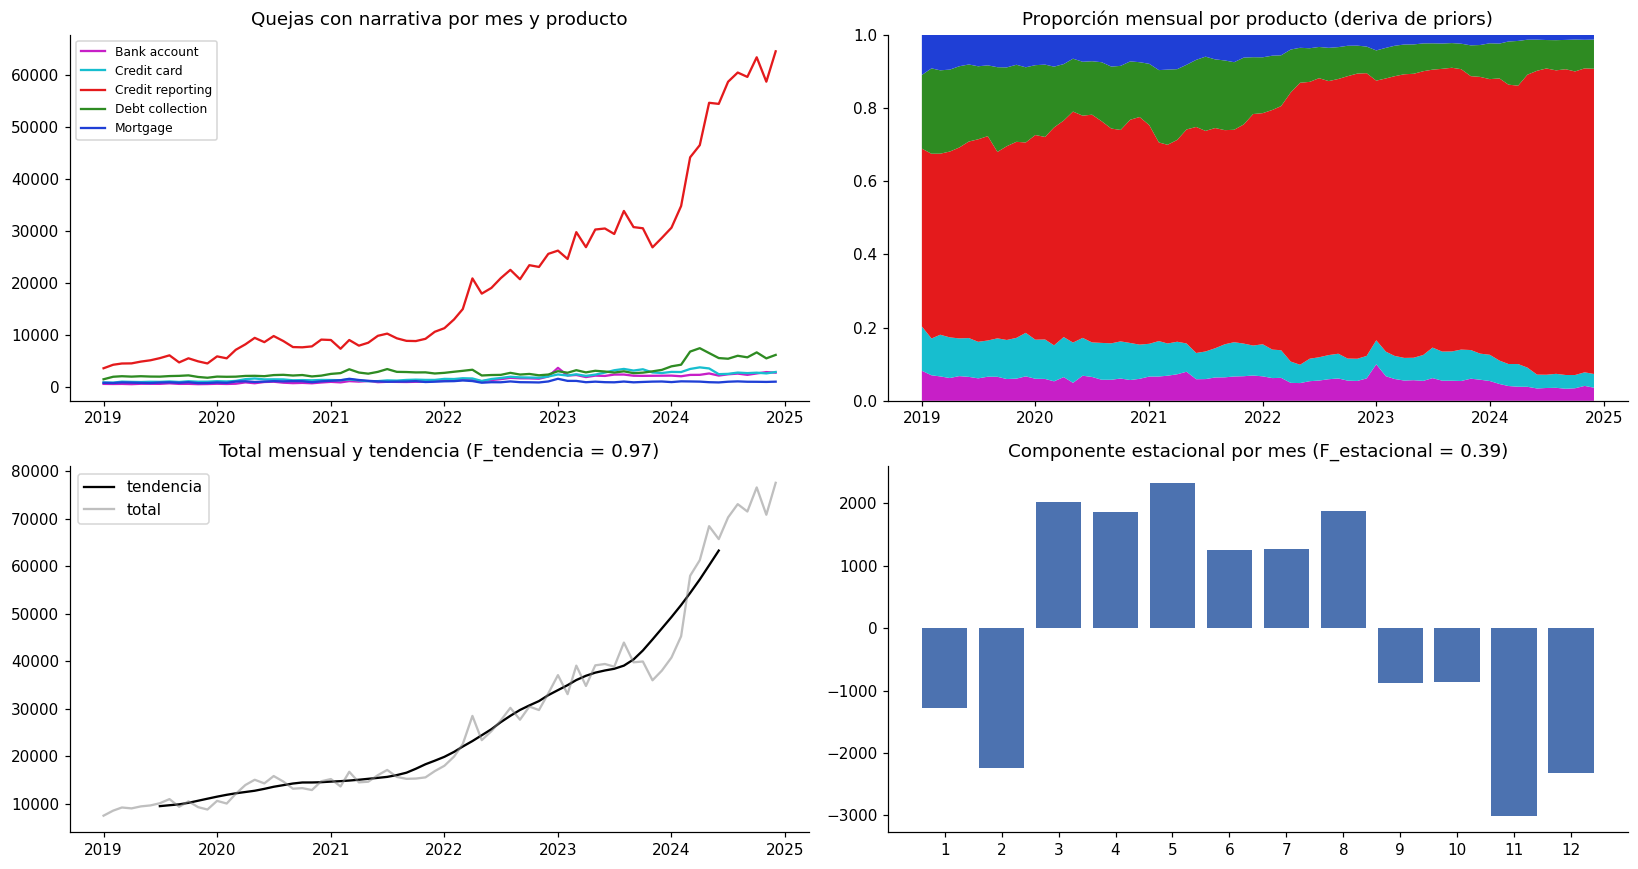

Fuerza de estacionalidad F_s = 0.39  (≈0 nula, >0.64 fuerte según Hyndman & Athanasopoulos [16])
Fuerza de tendencia     F_t = 0.97


In [24]:
# ===== Descomposición de la serie de tiempo =====
from statsmodels.tsa.seasonal import seasonal_decompose
total = monthly.sum(axis=1).asfreq("MS").fillna(0)
dec = seasonal_decompose(total, model="additive", period=12)
F_s = max(0, 1 - np.var(dec.resid.dropna()) / np.var((dec.seasonal + dec.resid).dropna()))  # fuerza estacional [16]
F_t = max(0, 1 - np.var(dec.resid.dropna()) / np.var((dec.trend + dec.resid).dropna()))     # fuerza de tendencia

fig, ax = plt.subplots(2, 2, figsize=(15, 8))
for c in monthly.columns:
    ax[0, 0].plot(monthly.index, monthly[c], color=CLASS_COLORS[c], label=c)
ax[0, 0].set_title("Quejas con narrativa por mes y producto"); ax[0, 0].legend(fontsize=8)
share = monthly.div(monthly.sum(axis=1), axis=0)
ax[0, 1].stackplot(share.index, share.T.values, colors=[CLASS_COLORS[c] for c in share.columns], labels=share.columns)
ax[0, 1].set_title("Proporción mensual por producto (deriva de priors)"); ax[0, 1].set_ylim(0, 1)
ax[1, 0].plot(dec.trend, color="k", label="tendencia"); ax[1, 0].plot(total, color="gray", alpha=.5, label="total")
ax[1, 0].set_title(f"Total mensual y tendencia (F_tendencia = {F_t:.2f})"); ax[1, 0].legend()
ax[1, 1].bar(range(1, 13), dec.seasonal.groupby(dec.seasonal.index.month).mean().values, color="#4C72B0")
ax[1, 1].set_xticks(range(1, 13)); ax[1, 1].set_title(f"Componente estacional por mes (F_estacional = {F_s:.2f})")
plt.tight_layout(); plt.show()
print(f"Fuerza de estacionalidad F_s = {F_s:.2f}  (≈0 nula, >0.64 fuerte según Hyndman & Athanasopoulos [16])")
print(f"Fuerza de tendencia     F_t = {F_t:.2f}")

### 📝 Discusión: estacionalidad

La descomposición aditiva (periodo 12) [15], [16] separa tendencia, estacionalidad y residuo. El valor impreso de **F_s** cuantifica la estacionalidad: valores bajos indican que el patrón anual es débil frente a la **tendencia**, que suele ser el componente dominante (crecimiento fuerte de quejas de *Credit reporting* a partir de 2020‑2022). La proporción de clases **cambia en el tiempo** (*prior shift*): esto no invalida un clasificador de texto (las palabras de cada producto son estables), pero implica que en producción conviene **re‑entrenar periódicamente** y vigilar la calibración. Como el objetivo no es pronosticar volúmenes, la división train/test es aleatoria estratificada.

## ✅ 4. Preprocesamiento de texto <a id='4'></a>

1. **Limpieza**: minúsculas; eliminación de las máscaras de anonimización de la CFPB (`XXXX`, `XX/XX/XXXX`), montos `{$100.00}`, dígitos y signos.
2. **Lematización** con spaCy `en_core_web_sm` [13] (*paid, paying → pay*).
3. **Eliminación de stop words** (lista de spaCy) y tokens de < 3 letras.

Este preprocesamiento es determinista por documento (no aprende nada de los datos), por lo que puede hacerse **antes** del *split* sin fuga de información. Todo lo que sí aprende de los datos (vocabulario e IDF) está **dentro del Pipeline** y se ajusta solo con el fold de entrenamiento.

El siguiente código define la función `clean()` con dos expresiones regulares (`RE_MASK` para las máscaras y montos, `RE_NONAL` para todo lo que no sea letra), lematiza los textos con `nlp.pipe` y guarda el resultado en caché (`cfpb_lemmas.parquet`), porque la lematización es el paso más lento del notebook. Al final se muestran tres ejemplos del texto original frente al texto limpio.

In [25]:
# ===== Limpieza, lematización y stop words =====
import spacy
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
RE_MASK  = re.compile(r"\bx{2,}(?:/x{2,})*\b|\{\$[\d,\.]+\}", flags=re.I)
RE_NONAL = re.compile(r"[^a-z\s]")

def clean(t: str) -> str:
    t = RE_MASK.sub(" ", t.lower())
    return re.sub(r"\s+", " ", RE_NONAL.sub(" ", t)).strip()

LEMMA_PATH = os.path.join(DATA_DIR, f"cfpb_lemmas_{SAMPLE_TAG}.parquet")
if os.path.exists(LEMMA_PATH) and len(pd.read_parquet(LEMMA_PATH)) == len(df):
    df["clean"] = pd.read_parquet(LEMMA_PATH)["clean"].values
else:
    t0 = time.time()
    texts = [clean(t)[:6000] for t in df["text"]]   # se truncan textos extremos para acotar tiempo
    df["clean"] = [" ".join(tok.lemma_ for tok in doc
                            if tok.is_alpha and not tok.is_stop and len(tok) > 2)
                   for doc in nlp.pipe(texts, batch_size=256, n_process=2)]
    df[["clean"]].to_parquet(LEMMA_PATH)
    print(f"Lematización: {time.time()-t0:.0f}s")
df = df[df["clean"].str.len() > 0].reset_index(drop=True)
print(df[["text", "clean"]].head(3).to_string(max_colwidth=90))

Lematización: 206s
                                                                                        text                                                                                      clean
0  I recently reviewed a copy of my credit report and notice I had fraudulent accounts on...  recently review copy credit report notice fraudulent account report remove account rep...
1  I notified regions bank of multiple fraud charges on my account and they denied them s...  notify region bank multiple fraud charge account deny state time pass charge take plac...
2  Bank of America authorized a creditor to offset balance of a company I was working for...  bank america authorize creditor offset balance company work money personal checking ac...


### ✅ 4.1 Word cloud y palabras frecuentes

El siguiente código genera una nube de palabras [17] con todas las quejas ya lematizadas y una nube por cada clase, coloreada con el color de la clase. En las nubes, el tamaño de cada palabra es proporcional a su frecuencia.

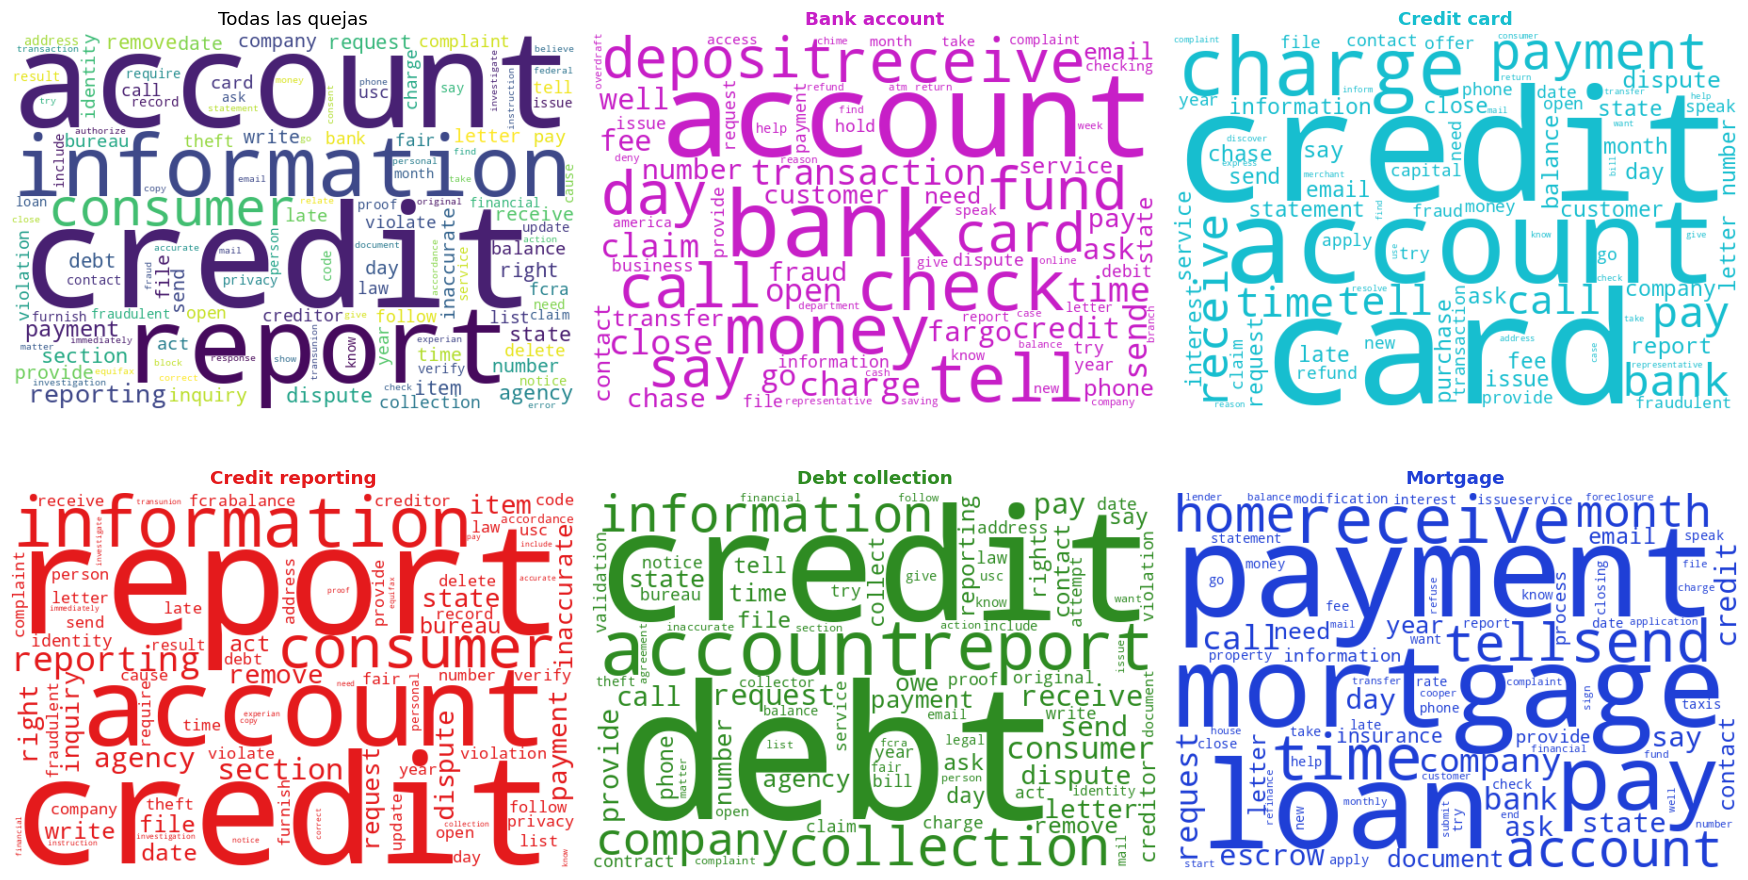

In [26]:
# ===== Word clouds: global y por clase =====
from wordcloud import WordCloud
classes = sorted(df["label"].unique())
fig = plt.figure(figsize=(16, 9))
ax0 = fig.add_subplot(2, 3, 1)
ax0.imshow(WordCloud(width=600, height=400, background_color="white", max_words=120, random_state=SEED,
                     collocations=False).generate(" ".join(df["clean"])), interpolation="bilinear")
ax0.set_title("Todas las quejas"); ax0.axis("off")
for i, c in enumerate(classes, start=2):
    a = fig.add_subplot(2, 3, i)
    col = CLASS_COLORS[c]
    a.imshow(WordCloud(width=600, height=400, background_color="white", max_words=80, random_state=SEED,
                       collocations=False, color_func=lambda *args, **kw: col)
             .generate(" ".join(df.loc[df.label == c, "clean"])), interpolation="bilinear")
    a.set_title(c, color=col, fontweight="bold"); a.axis("off")
plt.tight_layout(); plt.show()

El siguiente código cuenta unigramas y bigramas con `CountVectorizer` (solo términos que aparecen en al menos 5 quejas), grafica los 20 más frecuentes de cada tipo y construye una tabla con las 10 palabras más frecuentes por clase.

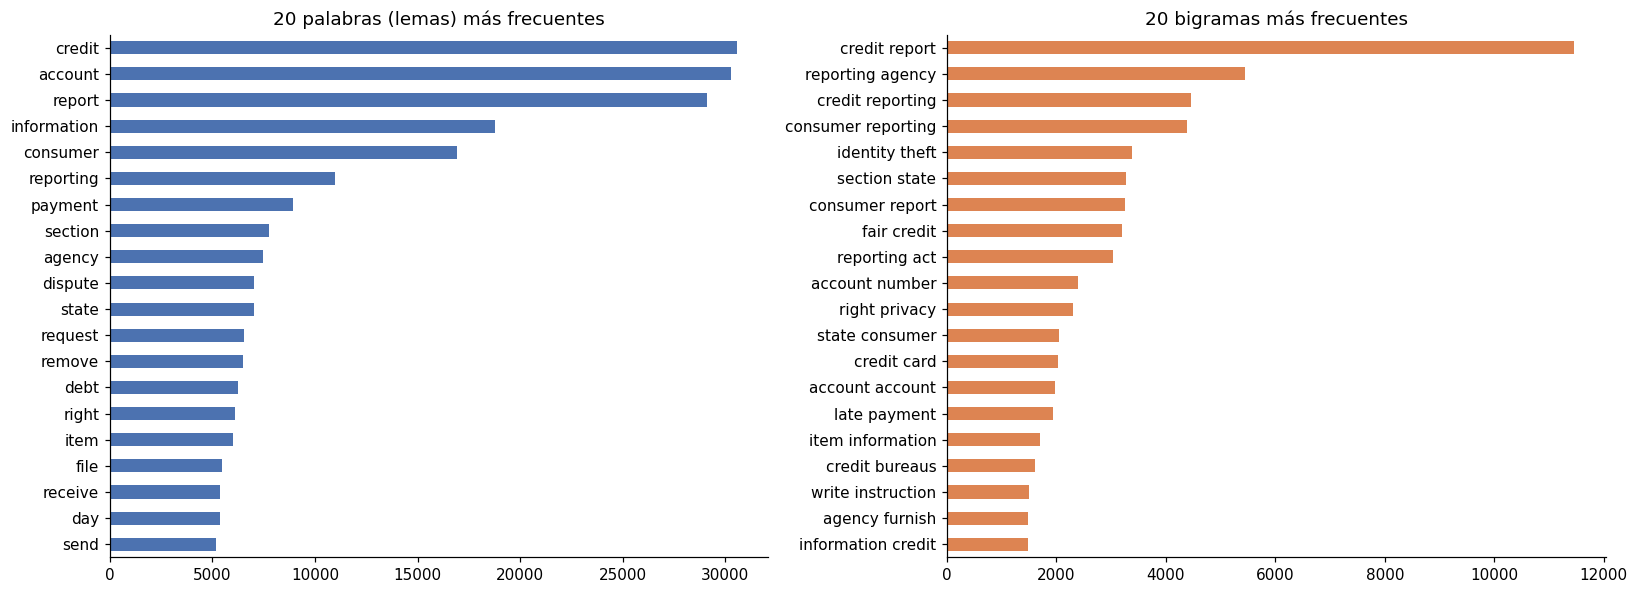

,Bank account,Credit card,Credit reporting,Debt collection,Mortgage
0,account,credit,report,debt,payment
1,bank,card,credit,credit,loan
2,check,account,account,account,mortgage
3,money,charge,information,report,pay
4,tell,payment,consumer,collection,receive
5,receive,receive,reporting,information,time
6,call,bank,section,company,send
7,day,pay,agency,consumer,account
8,fund,time,remove,receive,tell
9,deposit,tell,item,pay,home


In [27]:
# ===== Palabras y bigramas más frecuentes =====
cv1 = CountVectorizer(ngram_range=(1, 1), min_df=5); X1 = cv1.fit_transform(df["clean"])
cv2 = CountVectorizer(ngram_range=(2, 2), min_df=5); X2 = cv2.fit_transform(df["clean"])
top1 = pd.Series(X1.sum(0).A1, index=cv1.get_feature_names_out()).nlargest(20)
top2 = pd.Series(X2.sum(0).A1, index=cv2.get_feature_names_out()).nlargest(20)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
top1[::-1].plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("20 palabras (lemas) más frecuentes")
top2[::-1].plot.barh(ax=ax[1], color="#DD8452"); ax[1].set_title("20 bigramas más frecuentes")
plt.tight_layout(); plt.show()

# palabras más frecuentes por clase
per_class = {c: pd.Series(X1[(df.label == c).values].sum(0).A1, index=cv1.get_feature_names_out()).nlargest(10).index.tolist()
             for c in classes}
pd.DataFrame(per_class)

### 📝 Discusión: palabras frecuentes

Las palabras globales más frecuentes (*account, credit, report, payment…*) son compartidas por varias clases; las nubes por clase muestran vocabulario **discriminativo** (p. ej., *escrow/loan/modification* en hipotecas, *debt/collector/validation* en cobranzas, *bureau/inquiry/report* en reportes de crédito). Los bigramas (*credit report*, *identity theft*…) aportan contexto, por lo que el vectorizador usa `ngram_range=(1, 2)`. Se anticipa confusión entre *Credit reporting* y *Debt collection* (las deudas en cobranza aparecen en el reporte de crédito) y entre *Credit card* y *Bank account*.

## ✅ 5. Pipelines de sklearn <a id='5'></a>

Se separa un **20 % de test** estratificado que no se toca hasta la evaluación final. Ambos modelos comparten exactamente el mismo bloque TF‑IDF [22]:

```
Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=5, max_df=0.9, sublinear_tf=True)),
          ("clf",   LogisticRegression(C=1/λ))      |   MultinomialNB(alpha)])
```

* **Regresión Logística multinomial** minimiza la entropía cruzada + λ‖w‖²/2 (regularización L2; en sklearn `C = 1/λ`) [2], [6].
* **Naive Bayes Multinomial** modela P(palabra | clase) con suavizado de Laplace/Lidstone α [5]. α cumple un rol análogo a la regularización.

El siguiente código:

1. Convierte el texto limpio y las etiquetas a arreglos `numpy` de tipo `object` (con pandas 3.x los *strings* de pyarrow rompen `GridSearchCV`).
2. Divide los **índices** en train/test de forma estratificada (se guardan para recuperar el texto original en t‑SNE).
3. Define `TFIDF_PARAMS` y las funciones `make_lr()` y `make_nb()`, que construyen cada `Pipeline` y permiten cambiar su hiperparámetro (λ o α) y los parámetros del TF‑IDF.

In [28]:
# ===== División train/test y construcción de los pipelines =====
X, y = df["clean"].to_numpy(dtype=object), df["label"].to_numpy(dtype=object)
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
TFIDF_PARAMS = dict(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=60000, dtype=np.float32)

def make_lr(C=1.0, **tfidf):
    return Pipeline([("tfidf", TfidfVectorizer(**{**TFIDF_PARAMS, **tfidf})),
                     ("clf", LogisticRegression(C=C, max_iter=3000))], memory=memory)

def make_nb(alpha=1.0, **tfidf):
    return Pipeline([("tfidf", TfidfVectorizer(**{**TFIDF_PARAMS, **tfidf})),
                     ("clf", MultinomialNB(alpha=alpha))], memory=memory)

print(f"train={len(X_train):,}  test={len(X_test):,}")
make_lr()

train=11,996  test=3,000


Pipeline(memory=Memory(location=/tmp/cfpb_sk_cache/joblib),
         steps=[('tfidf',
                 TfidfVectorizer(dtype=<class 'numpy.float32'>, max_df=0.9,
                                 max_features=60000, min_df=5,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('clf', LogisticRegression(max_iter=3000))])

## ✅ 6. Optimización de hiperparámetros con *repeated stratified k‑fold CV* <a id='6'></a>

Se barre λ en escala logarítmica con `GridSearchCV` y `RepeatedStratifiedKFold(5 folds × 2 repeticiones)` sobre el conjunto de entrenamiento, registrando **la pérdida (log‑loss) de entrenamiento y de validación** (`return_train_score=True`). El mejor λ es el que minimiza la **CV loss**. No se usa *nested CV* por su costo computacional (indicación del enunciado).

El siguiente código define `search_with_widening()`, un envoltorio de `GridSearchCV` que además **verifica que el mejor valor no quede en el borde de la grilla**: si el óptimo cae en un extremo y la *CV loss* todavía mejora (más de 0.001 respecto al punto vecino), amplía la grilla una década hacia ese lado (manteniendo el paso logarítmico) y repite la búsqueda, hasta 3 veces. Si la curva ya es plana en el borde, no amplía, porque un valor más extremo no cambiaría el modelo. Así el hiperparámetro elegido es un mínimo real de la *CV loss* y no un límite artificial del rango probado. Después se arma la tabla de resultados con λ = 1/C.

In [29]:
# ===== 6.0 Búsqueda de λ para Regresión Logística =====
def search_with_widening(make_model, param, values, to_param=lambda v: v, max_ext=3, tol=1e-3):
    """GridSearchCV (log-loss y macro-F1). Si el óptimo queda en un extremo y la CV loss sigue bajando
    (mejora > tol respecto al punto vecino), amplía la grilla una década hacia ese lado.
    Retorna (grid, valores probados, True si el óptimo quedó en el borde sin estabilizarse)."""
    values = np.asarray(values, dtype=float)
    for ext in range(max_ext + 1):
        gs = GridSearchCV(make_model(), {param: list(to_param(values))}, cv=CV_OPT, n_jobs=-1,
                          scoring={"logloss": "neg_log_loss", "f1": "f1_macro"}, refit="logloss",
                          return_train_score=True).fit(X_train, y_train)
        loss = -gs.cv_results_["mean_test_logloss"]
        i, n = gs.best_index_, len(values)
        if 0 < i < n - 1:
            return gs, values, False
        if abs(loss[i] - loss[1 if i == 0 else n - 2]) < tol:
            print(f"  el óptimo ({values[i]:.3g}) está en el borde, pero la CV loss ya es plana (Δ < {tol}): no se amplía")
            return gs, values, False
        if ext == max_ext:
            return gs, values, True
        lo, hi = np.log10(values[0]) - (i == 0), np.log10(values[-1]) + (i == n - 1)
        print(f"  el óptimo ({values[i]:.3g}) está en el borde de la grilla -> se amplía a [{10**lo:.0e}, {10**hi:.0e}]")
        values = np.logspace(lo, hi, n + 2)

t0 = time.time()
gs_lr, lambdas, lr_at_edge = search_with_widening(make_lr, "clf__C", np.logspace(-3, 2, 11), to_param=lambda v: 1 / v)
r = pd.DataFrame(gs_lr.cv_results_)
r["lambda"] = 1 / r["param_clf__C"].astype(float)
r = r.sort_values("lambda")
best_lambda = 1 / gs_lr.best_params_["clf__C"]
print(f"[{time.time()-t0:.0f}s] Mejor λ = {best_lambda:.4g}  (C = {1/best_lambda:.4g}) | "
      f"CV log-loss = {-gs_lr.best_score_:.4f} | CV macro-F1 = {r.loc[r['lambda']==best_lambda,'mean_test_f1'].item():.4f}")
r[["lambda", "mean_train_logloss", "mean_test_logloss", "mean_test_f1"]].assign(
    mean_train_logloss=lambda d: -d.mean_train_logloss, mean_test_logloss=lambda d: -d.mean_test_logloss).round(4)

[533s] Mejor λ = 0.1  (C = 10) | CV log-loss = 0.2964 | CV macro-F1 = 0.8253


,lambda,mean_train_logloss,mean_test_logloss,mean_test_f1
0,0.0010,0.0127,0.5071,0.8258
1,0.0032,0.0150,0.4107,0.8239
2,0.0100,0.0220,0.3493,0.8258
3,0.0316,0.0374,0.3130,0.8265
4,0.1000,0.0720,0.2964,0.8253
5,0.3162,0.1416,0.3024,0.8262
6,1.0000,0.2467,0.3404,0.8080
7,3.1623,0.3771,0.4219,0.7507
8,10.0000,0.5367,0.5550,0.4209
9,31.6228,0.7043,0.7106,0.1692


El siguiente código define `plot_hparam_curve()`, que dibuja la curva de optimización de λ con el estilo de la diapositiva *Regularization* del curso [7]: *CV loss* en magenta, *training loss* en azul, bandas de ±1 desviación estándar entre folds, las zonas de **alta varianza (overfit)** y **alto sesgo (underfit)**, y el punto verde *"just right"* en el mínimo de la *CV loss*.

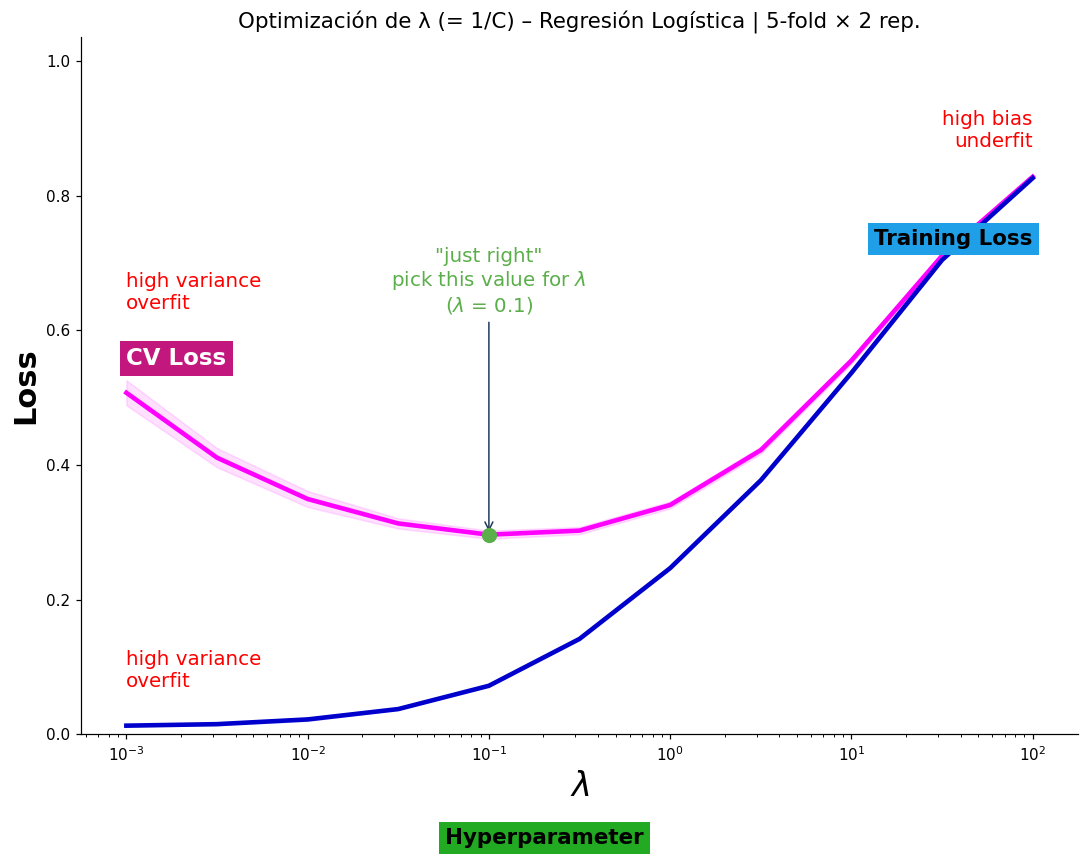

In [30]:
# ===== Gráfica de optimización del hiperparámetro (estilo del curso) =====
def plot_hparam_curve(x, train_loss, cv_loss, best_x, train_std=None, cv_std=None,
                      xlabel=r"$\lambda$", title="Optimización de λ – Regresión Logística"):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.plot(x, cv_loss, color="#FF00FF", lw=3)
    ax.plot(x, train_loss, color="#0000CD", lw=3)
    if cv_std is not None:
        ax.fill_between(x, cv_loss - cv_std, cv_loss + cv_std, color="#FF00FF", alpha=.12)
        ax.fill_between(x, train_loss - train_std, train_loss + train_std, color="#0000CD", alpha=.12)
    ax.set_xscale("log")
    ymax = max(cv_loss.max(), train_loss.max()); ymin = min(train_loss.min(), 0)
    ax.set_ylim(ymin, ymax * 1.25)
    # etiquetas tipo diapositiva
    ax.text(x[0], cv_loss[0] + .05 * ymax, "CV Loss", color="white", fontsize=15, fontweight="bold",
            bbox=dict(facecolor="#C2187D", edgecolor="none"))
    ax.text(x[-1], train_loss[-1] - .12 * ymax, "Training Loss", color="black", fontsize=14, fontweight="bold",
            ha="right", bbox=dict(facecolor="#1E9FE8", edgecolor="none"))
    ax.text(x[0], cv_loss[0] + .15 * ymax, "high variance\noverfit", color="red", fontsize=13)
    ax.text(x[0], train_loss[0] + .07 * ymax, "high variance\noverfit", color="red", fontsize=13)
    ax.text(x[-1], ymax * 1.12, "high bias\nunderfit", color="red", fontsize=13, ha="right", va="top")
    i = int(np.argmin(np.abs(x - best_x)))
    ax.annotate(f"\"just right\"\npick this value for {xlabel}\n({xlabel} = {best_x:.3g})",
                xy=(x[i], cv_loss[i]), xytext=(x[i], cv_loss[i] + .40 * ymax),
                ha="center", color="#5BAF4A", fontsize=13,
                arrowprops=dict(arrowstyle="->", color="#1F3B5A"))
    ax.scatter([x[i]], [cv_loss[i]], s=80, color="#5BAF4A", zorder=5)
    ax.set_xlabel(xlabel, fontsize=22); ax.set_ylabel("Loss", fontsize=20, fontweight="bold")
    ax.set_title(title, fontsize=14)
    fig.text(0.5, -0.03, "Hyperparameter", ha="center", fontsize=14, fontweight="bold",
             bbox=dict(facecolor="#22AA22", edgecolor="none"))
    plt.tight_layout(); plt.show()

plot_hparam_curve(r["lambda"].values, -r["mean_train_logloss"].values, -r["mean_test_logloss"].values, best_lambda,
                  r["std_train_logloss"].values, r["std_test_logloss"].values,
                  xlabel=r"$\lambda$", title="Optimización de λ (= 1/C) – Regresión Logística | 5-fold × 2 rep.")

### 📝 Discusión: optimización de λ (sesgo / varianza)

Con **λ pequeño** (poca regularización) la *training loss* es muy baja mientras la *CV loss* es mayor → **alta varianza / overfit**. A medida que λ crece, la brecha se cierra y la CV loss alcanza su mínimo (λ "*just right*"). Con **λ grande** ambas pérdidas suben juntas → **alto sesgo / underfit** (el modelo tiende a predecir las probabilidades a priori). La banda sombreada es ±1 desviación estándar entre los 10 folds. El λ con menor *CV loss* es el que se usa en los modelos finales (ver sección 6.3).

### 6.1 Hiperparámetro de Naive Bayes (α de suavizado)

El siguiente código repite el procedimiento para Naive Bayes Multinomial: busca α con `search_with_widening()` (misma validación cruzada, mismo criterio log‑loss y misma verificación de borde de grilla) y reutiliza `plot_hparam_curve()` para graficar la curva de α.

Mejor α = 0.3162 | CV log-loss = 0.3900 | CV macro-F1 = 0.8061


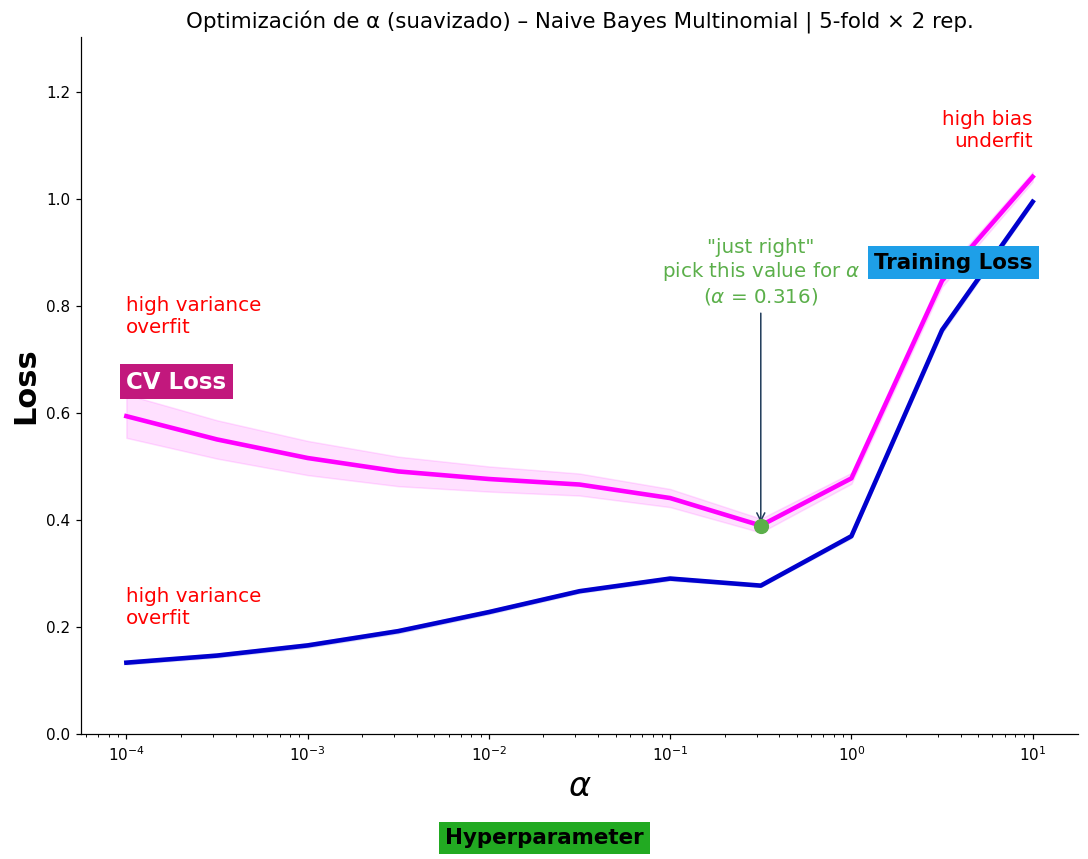

In [31]:
# ===== 6.1 Búsqueda de α para Naive Bayes =====
gs_nb, alphas, nb_at_edge = search_with_widening(make_nb, "clf__alpha", np.logspace(-4, 1, 11))
rn = pd.DataFrame(gs_nb.cv_results_).sort_values("param_clf__alpha")
best_alpha = gs_nb.best_params_["clf__alpha"]
print(f"Mejor α = {best_alpha:.4g} | CV log-loss = {-gs_nb.best_score_:.4f} | "
      f"CV macro-F1 = {rn.loc[rn.param_clf__alpha==best_alpha,'mean_test_f1'].item():.4f}")
plot_hparam_curve(rn["param_clf__alpha"].astype(float).values, -rn["mean_train_logloss"].values,
                  -rn["mean_test_logloss"].values, best_alpha, rn["std_train_logloss"].values,
                  rn["std_test_logloss"].values, xlabel=r"$\alpha$",
                  title="Optimización de α (suavizado) – Naive Bayes Multinomial | 5-fold × 2 rep.")

### 📝 Discusión: optimización de α

α tiene el mismo papel que λ: con **α muy pequeño** el modelo confía casi por completo en las frecuencias observadas en entrenamiento (las palabras raras reciben probabilidades extremas → **varianza**), y con **α grande** el suavizado aplana P(palabra | clase) hacia una distribución uniforme y el modelo pierde capacidad de discriminar (**sesgo**). El α con menor *CV loss* es el que se usa en los modelos finales.

### 6.2 (Extra) Optimización conjunta con Optuna

Optuna [14] usa un muestreador bayesiano (TPE) para explorar simultáneamente λ y parámetros del vectorizador TF‑IDF (`min_df`, tamaño de n‑gramas y `sublinear_tf`), con la misma validación *repeated stratified k‑fold*.

El siguiente código define la función objetivo (CV log‑loss media de la Regresión Logística), agrega como primer *trial* el mejor punto del grid (para que Optuna nunca termine peor que el grid) y grafica el historial de la optimización y la importancia de cada parámetro.

Mejores parámetros Optuna: {'lambda': 0.14587246767000075, 'min_df': 6, 'ngram_max': 2, 'sublinear_tf': True} | CV log-loss = 0.2956


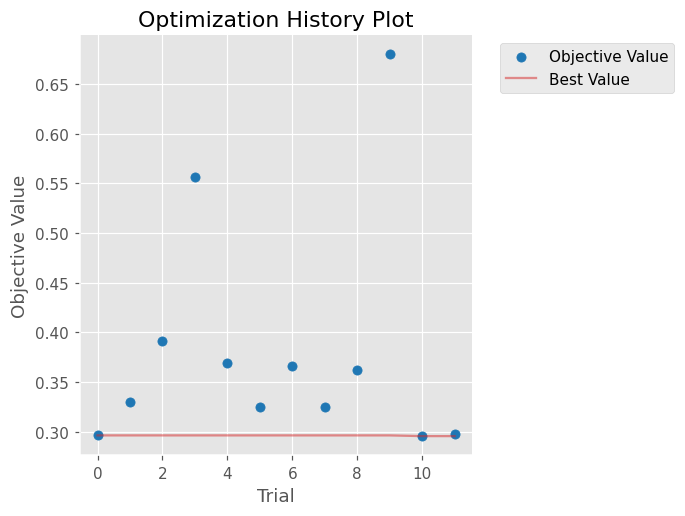

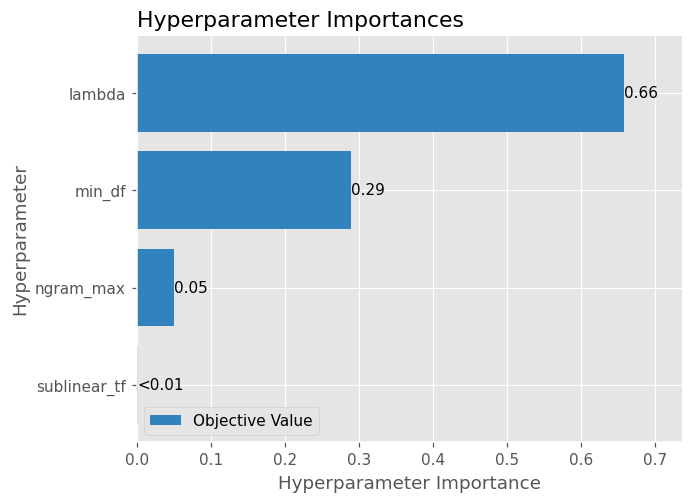

In [32]:
# ===== 6.2 Optuna: λ + parámetros del TF-IDF =====
if RUN_OPTUNA:
    import optuna
    from sklearn.model_selection import cross_val_score
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    lam_lo = min(1e-3, lambdas.min())   # el rango incluye el mejor λ del grid aunque la grilla se haya ampliado

    def objective(trial):
        lam = trial.suggest_float("lambda", lam_lo, 1e1, log=True)
        tf = dict(min_df=trial.suggest_int("min_df", 2, 10),
                  ngram_range=(1, trial.suggest_int("ngram_max", 1, 2)),
                  sublinear_tf=trial.suggest_categorical("sublinear_tf", [True, False]))
        return -cross_val_score(make_lr(C=1 / lam, **tf), X_train, y_train, cv=CV_OPT,
                                scoring="neg_log_loss", n_jobs=-1).mean()

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.enqueue_trial({"lambda": best_lambda, "min_df": 5, "ngram_max": 2, "sublinear_tf": True})  # punto del grid
    study.optimize(objective, n_trials=OPTUNA_TRIALS, show_progress_bar=False)
    print("Mejores parámetros Optuna:", study.best_params, f"| CV log-loss = {study.best_value:.4f}")
    from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
    plot_optimization_history(study); plt.show()
    try:
        plot_param_importances(study); plt.show()
    except Exception as e:
        print("Importancias no disponibles:", e)
    # optuna aplica el estilo 'ggplot' globalmente: se restaura el estilo por defecto
    plt.style.use("default")
    plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### 📝 Discusión: Optuna

Si Optuna encuentra una combinación con menor *CV log‑loss* que el grid, la mejora proviene principalmente de los parámetros del vectorizador (ver gráfico de importancias). En ese caso, la siguiente sección **adopta esos hiperparámetros** para los modelos finales.

### ✅ 6.3 Selección de los hiperparámetros finales

Esta celda garantiza que **el mejor hiperparámetro encontrado sea el que se usa** en todo lo que sigue (curva de aprendizaje, comparación estadística, evaluación en test y t‑SNE). El siguiente código:

1. Compara la *CV log‑loss* del mejor λ del grid con la del mejor *trial* de Optuna (misma validación cruzada y mismo criterio) y se queda con la configuración de menor pérdida, incluyendo sus parámetros de TF‑IDF.
2. Para que la comparación entre modelos sea **justa**, Naive Bayes usa **el mismo TF‑IDF** que la Regresión Logística. Si ese TF‑IDF cambió respecto al del grid, se vuelve a buscar α sobre él.
3. Construye los modelos finales `best_lr` y `best_nb` y muestra una tabla con los hiperparámetros elegidos.

In [33]:
# ===== 6.3 Hiperparámetros finales (los que se usan en las secciones 7-10) =====
DEFAULT_TFIDF = dict(min_df=5, ngram_range=(1, 2), sublinear_tf=True)

# ---- 1. Regresión Logística: mejor configuración entre grid y Optuna ----
if RUN_OPTUNA and study.best_value < -gs_lr.best_score_:
    hp_source, final_lambda, final_lr_loss = "Optuna", study.best_params["lambda"], study.best_value
    FINAL_TFIDF = dict(min_df=study.best_params["min_df"], ngram_range=(1, study.best_params["ngram_max"]),
                       sublinear_tf=study.best_params["sublinear_tf"])
else:
    hp_source, final_lambda, final_lr_loss, FINAL_TFIDF = "GridSearchCV", best_lambda, -gs_lr.best_score_, DEFAULT_TFIDF

# ---- 2. Naive Bayes: α sobre el mismo TF-IDF ----
if FINAL_TFIDF == DEFAULT_TFIDF:
    final_alpha, final_nb_loss = best_alpha, -gs_nb.best_score_
else:
    gs_nb_final = GridSearchCV(make_nb(**FINAL_TFIDF), {"clf__alpha": list(alphas)}, cv=CV_OPT, n_jobs=-1,
                               scoring="neg_log_loss").fit(X_train, y_train)
    final_alpha, final_nb_loss = gs_nb_final.best_params_["clf__alpha"], -gs_nb_final.best_score_

# ---- 3. Modelos finales ----
best_lr = make_lr(C=1 / final_lambda, **FINAL_TFIDF)
best_nb = make_nb(alpha=final_alpha, **FINAL_TFIDF)
tfidf_txt = (f"min_df={FINAL_TFIDF['min_df']}, ngram_range={FINAL_TFIDF['ngram_range']}, "
             f"sublinear_tf={FINAL_TFIDF['sublinear_tf']}")
display(pd.DataFrame({
    "Regresión Logística": {"origen": hp_source, "hiperparámetro": f"λ = {final_lambda:.4g} (C = {1/final_lambda:.4g})",
                            "TF-IDF": tfidf_txt, "CV log-loss": round(final_lr_loss, 4)},
    "Naive Bayes": {"origen": "GridSearchCV" + ("" if FINAL_TFIDF == DEFAULT_TFIDF else " (sobre el TF-IDF de Optuna)"),
                    "hiperparámetro": f"α = {final_alpha:.4g}",
                    "TF-IDF": tfidf_txt, "CV log-loss": round(final_nb_loss, 4)}}).T)

,origen,hiperparámetro,TF-IDF,CV log-loss
Regresión Logística,Optuna,λ = 0.1459 (C = 6.855),"min_df=6, ngram_range=(1, 2), sublinear_tf=True",0.2956
Naive Bayes,GridSearchCV (sobre el TF-IDF de Optuna),α = 0.3162,"min_df=6, ngram_range=(1, 2), sublinear_tf=True",0.3967


### 📝 Discusión: hiperparámetros finales

La tabla anterior resume los hiperparámetros que se usan desde aquí en adelante. Todos se eligieron **solo con el conjunto de entrenamiento** (validación cruzada), sin mirar el test. Ambos modelos comparten la misma representación TF‑IDF y cada uno usa su propio hiperparámetro óptimo (λ o α), de modo que las diferencias que se observen en las secciones 7‑9 se deben al modelo y no a la representación.

## ✅ 7. Curva de aprendizaje <a id='7'></a>

Se entrenan los modelos finales (sección 6.3) con fracciones crecientes *m* del conjunto de entrenamiento, usando el mismo esquema *repeated stratified k‑fold* [21]. La línea verde es el desempeño deseado (`DESIRED_LOSS`).

El siguiente código define `plot_learning_curve()`, que:

1. Calcula la *training loss* y la *CV loss* para 8 tamaños de entrenamiento con `learning_curve`.
2. Emite un diagnóstico: **High bias** si la *training loss* final supera el objetivo; **High variance** si la *CV loss* supera el objetivo y el *gap* es grande; **Good fit** en otro caso.
3. Dibuja la curva con el estilo de la diapositiva del curso [7]: *CV loss* en rojo, *training loss* en azul, la línea de desempeño deseado y la flecha del *gap* entre ambas curvas.

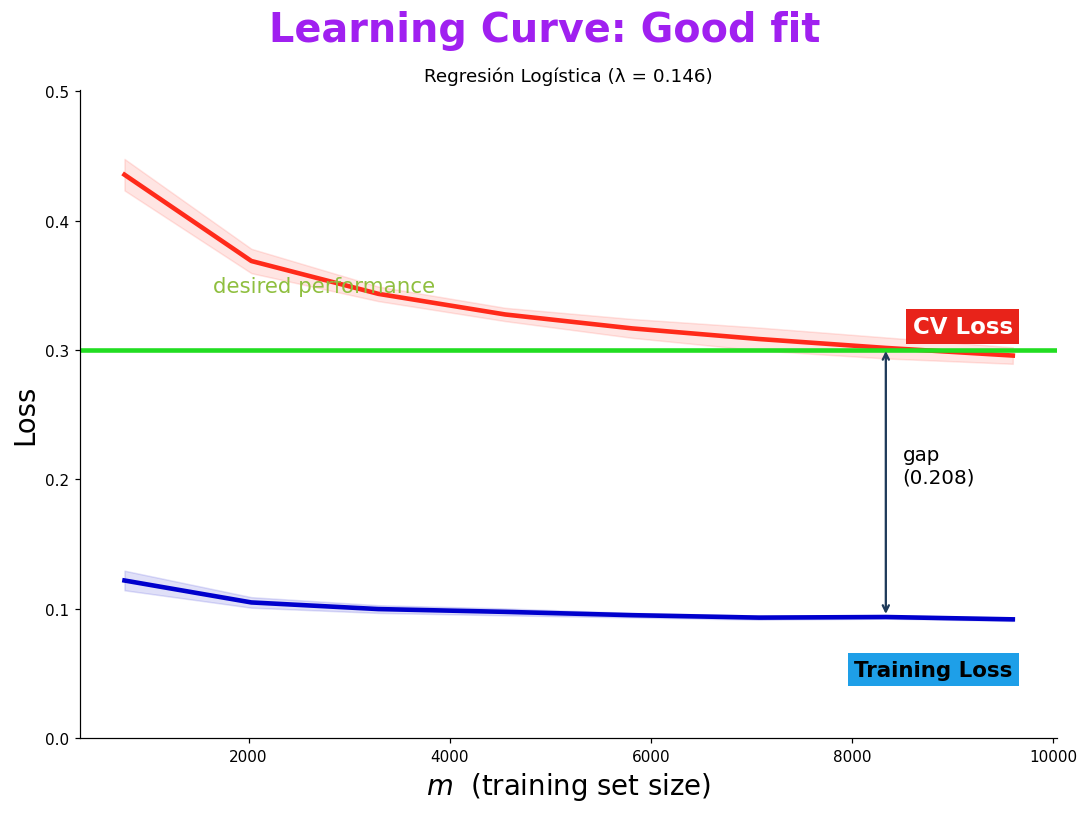

Regresión Logística (λ = 0.146): train loss=0.0918 | CV loss=0.2957 | gap=0.2038 | diagnóstico: Good fit


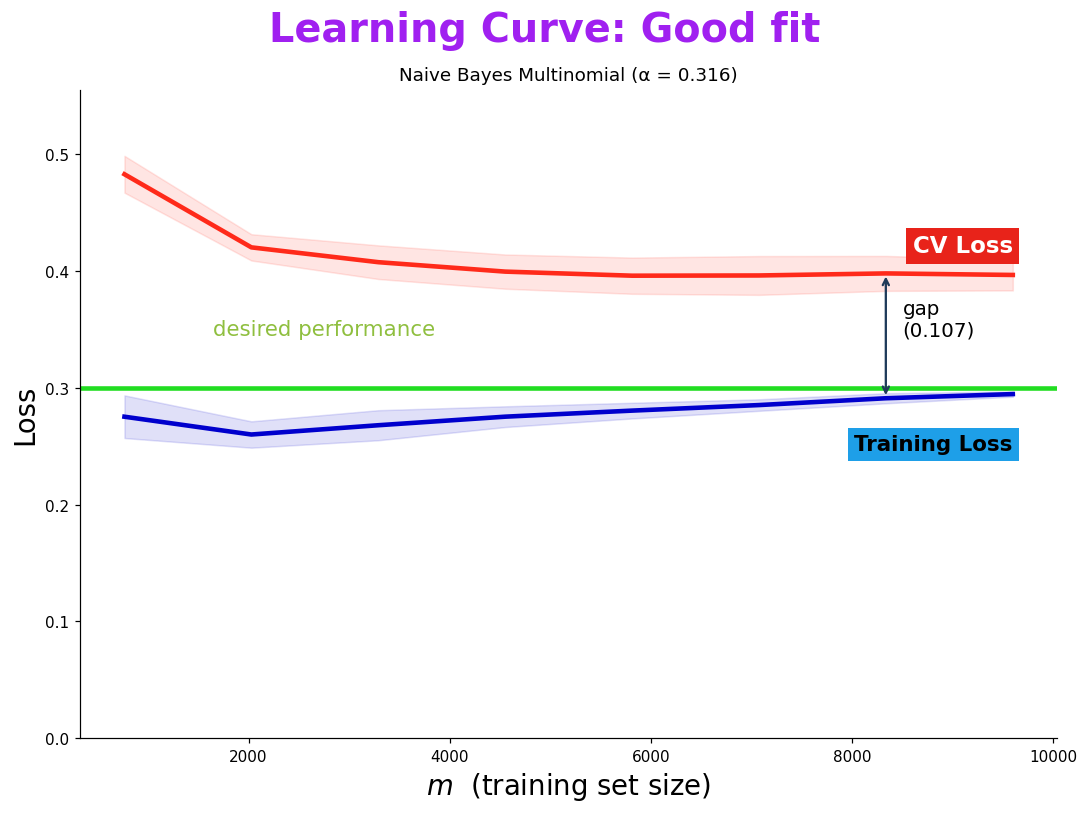

Naive Bayes Multinomial (α = 0.316): train loss=0.2947 | CV loss=0.3967 | gap=0.1020 | diagnóstico: Good fit


In [34]:
# ===== Curva de aprendizaje (estilo del curso) =====
def plot_learning_curve(model, name):
    sizes, tr, va = learning_curve(model, X_train, y_train, cv=CV_OPT, scoring="neg_log_loss",
                                   train_sizes=np.linspace(0.08, 1.0, 8), n_jobs=-1, shuffle=True,
                                   random_state=SEED)
    tr_m, va_m = -tr.mean(1), -va.mean(1)
    gap = va_m[-1] - tr_m[-1]
    if tr_m[-1] > DESIRED_LOSS:
        diag = "High bias"
    elif va_m[-1] > DESIRED_LOSS and gap > 0.5 * DESIRED_LOSS:
        diag = "High variance"
    else:
        diag = "Good fit"
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.plot(sizes, va_m, color="#FF2A1A", lw=3)
    ax.plot(sizes, tr_m, color="#0000CD", lw=3)
    ax.fill_between(sizes, va_m - va.std(1), va_m + va.std(1), color="#FF2A1A", alpha=.12)
    ax.fill_between(sizes, tr_m - tr.std(1), tr_m + tr.std(1), color="#0000CD", alpha=.12)
    ax.axhline(DESIRED_LOSS, color="#22DD22", lw=3)
    ax.text(sizes[0] + 0.1 * (sizes[-1] - sizes[0]), DESIRED_LOSS * 1.15, "desired performance",
            color="#8FBF3F", fontsize=14)
    ax.annotate("", xy=(sizes[-2], tr_m[-2]), xytext=(sizes[-2], va_m[-2]),
                arrowprops=dict(arrowstyle="<->", color="#1F3B5A", lw=1.5))
    ax.text(sizes[-2] * 1.02, (tr_m[-2] + va_m[-2]) / 2, f"gap\n({va_m[-2]-tr_m[-2]:.3f})", fontsize=13)
    ax.text(sizes[-1], va_m[-1] + .04 * va_m.max(), "CV Loss", color="white", fontsize=15, fontweight="bold",
            ha="right", bbox=dict(facecolor="#E8231A", edgecolor="none"))
    ax.text(sizes[-1], max(tr_m[-1] - .1 * va_m.max(), 0.005), "Training Loss", color="black", fontsize=14,
            fontweight="bold", ha="right", bbox=dict(facecolor="#1E9FE8", edgecolor="none"))
    ax.set_ylim(0, max(va_m.max(), DESIRED_LOSS) * 1.15)
    ax.set_xlabel(r"$m$  (training set size)", fontsize=18); ax.set_ylabel("Loss", fontsize=18)
    fig.suptitle(f"Learning Curve: {diag}", fontsize=26, fontweight="bold", color="#A020F0")
    ax.set_title(name, fontsize=12)
    plt.tight_layout(); plt.show()
    print(f"{name}: train loss={tr_m[-1]:.4f} | CV loss={va_m[-1]:.4f} | gap={gap:.4f} | diagnóstico: {diag}")
    return dict(sizes=sizes, train=tr_m, cv=va_m, gap=gap, diag=diag)

lc_lr = plot_learning_curve(best_lr, f"Regresión Logística (λ = {final_lambda:.3g})")
lc_nb = plot_learning_curve(best_nb, f"Naive Bayes Multinomial (α = {final_alpha:.3g})")

### 📝 Discusión: curva de aprendizaje

La *training loss* aumenta con *m* (es más difícil memorizar más ejemplos) y la *CV loss* disminuye (el modelo generaliza mejor con más datos). El tamaño del **gap** y la posición respecto a la línea verde indican el diagnóstico impreso en el título:
* *gap* grande con *training loss* bajo el objetivo → **alta varianza**: ayuda conseguir más datos o regularizar más;
* ambas curvas sobre el objetivo y juntas → **alto sesgo**: más datos no ayudan; se necesita un modelo/representación más rica.

## ✅ 8. Comparación estadística: Regresión Logística vs Naive Bayes <a id='8'></a>

* **Esquema:** `RepeatedStratifiedKFold(n_splits=10, n_repeats=10)` → 100 pares de puntajes (mismos folds para ambos modelos, por lo que las muestras son **pareadas**).
* **Modelos:** `best_lr` y `best_nb`, con los hiperparámetros finales de la sección 6.3.
* **Métrica principal:** macro‑F1 (dataset desbalanceado).
* **Hipótesis:** H₀: la mediana (o media) de la diferencia de macro‑F1 entre LR y NB es 0. H₁: es distinta de 0 (bilateral), α = 0.05.
* **Pruebas:**
  1. **Wilcoxon signed‑rank** [8] (no paramétrica, recomendada por Demšar [11]).
  2. **t‑test pareado corregido** de Nadeau & Bengio [9], [10], [23]: los folds de un *repeated k‑fold* se solapan, así que el t‑test clásico subestima la varianza; la corrección usa
     $t = \dfrac{\bar d}{\sqrt{\left(\frac{1}{k} + \frac{n_{test}}{n_{train}}\right)\hat\sigma^2_d}}$, con $k=100$ y $k-1$ grados de libertad.

El siguiente código evalúa ambos modelos con `cross_validate` sobre los mismos 100 folds y muestra una tabla con la media ± desviación estándar de macro‑F1, exactitud y log‑loss.

In [35]:
# ===== 10x10 repeated stratified k-fold para ambos modelos =====
scoring = {"f1_macro": "f1_macro", "accuracy": "accuracy", "neg_log_loss": "neg_log_loss"}
t0 = time.time()
cv_lr = cross_validate(best_lr, X_train, y_train, cv=CV_CMP, scoring=scoring, n_jobs=-1)
cv_nb = cross_validate(best_nb, X_train, y_train, cv=CV_CMP, scoring=scoring, n_jobs=-1)
print(f"Tiempo comparación: {time.time()-t0:.0f}s")

summary = pd.DataFrame({
    "LR": {m: f"{cv_lr['test_'+m].mean():.4f} ± {cv_lr['test_'+m].std():.4f}" for m in scoring},
    "NB": {m: f"{cv_nb['test_'+m].mean():.4f} ± {cv_nb['test_'+m].std():.4f}" for m in scoring}})
display(summary)

Tiempo comparación: 532s


,LR,NB
f1_macro,0.8257 ± 0.0172,0.8057 ± 0.0144
accuracy,0.9007 ± 0.0080,0.8854 ± 0.0079
neg_log_loss,-0.2923 ± 0.0179,-0.3978 ± 0.0312


El siguiente código aplica las pruebas de hipótesis sobre las 100 diferencias pareadas de macro‑F1 (d = LR − NB):

1. `corrected_ttest()` implementa el t‑test corregido de Nadeau & Bengio (basado en el ejemplo oficial de sklearn [23]).
2. Se calculan Wilcoxon, el t‑test clásico (solo como referencia) y el t‑test corregido, el número de folds en que gana LR y el tamaño de efecto *rank‑biserial*.
3. Se grafican los puntajes de ambos modelos (*boxplot*) y la distribución de las diferencias.

,estadístico,p-valor
Wilcoxon signed-rank,133.000,1.961e-16
"t-test pareado (clásico, referencia)",13.584,2.375e-24
t-test corregido Nadeau-Bengio,3.904,1.727e-04


Diferencia media macro-F1 (LR − NB) = +0.0201 | LR gana en 92/100 folds | rank-biserial r = 0.95
  Wilcoxon: Se RECHAZA H0 (α=0.05)
  t corregido: Se RECHAZA H0 (α=0.05)


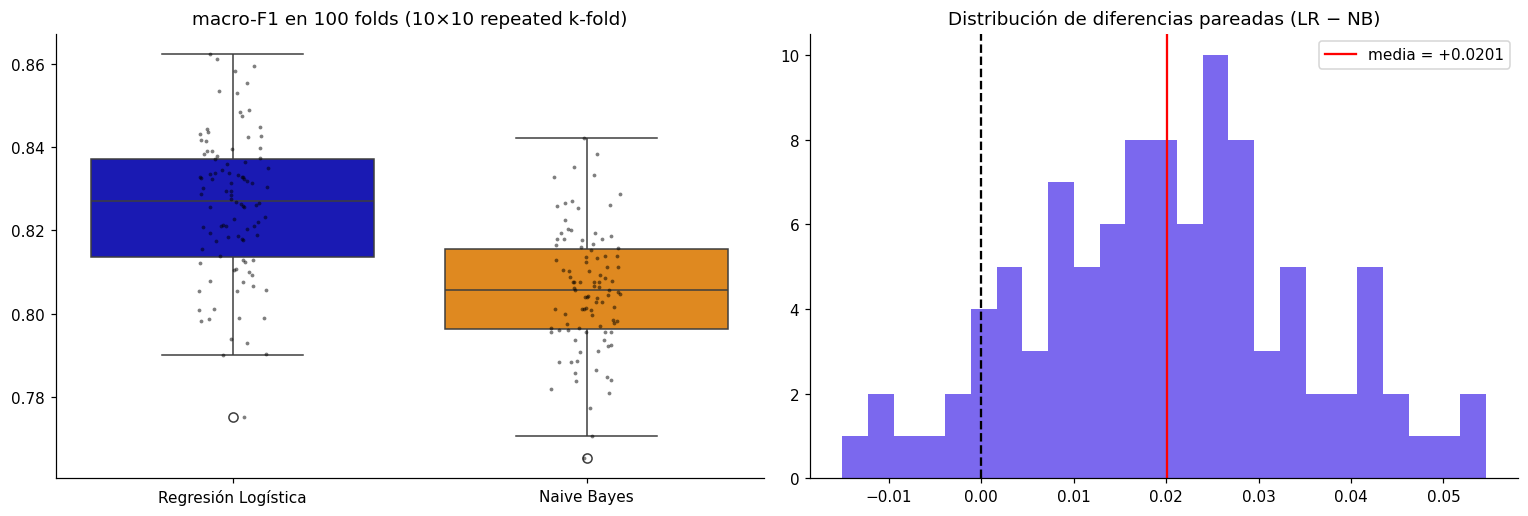

In [36]:
# ===== Pruebas de hipótesis =====
def corrected_ttest(d, n_train, n_test):
    """t-test pareado corregido (Nadeau & Bengio, 2003). Basado en el ejemplo oficial de sklearn [23]."""
    k = len(d)
    var = np.var(d, ddof=1) * (1 / k + n_test / n_train)
    t = d.mean() / np.sqrt(var)
    p = 2 * stats.t.sf(np.abs(t), df=k - 1)
    return t, p

a, b = cv_lr["test_f1_macro"], cv_nb["test_f1_macro"]
d = a - b
n_splits = CV_CMP.cvargs["n_splits"]
n_test = len(X_train) // n_splits; n_train = len(X_train) - n_test
w_stat, p_wil = stats.wilcoxon(a, b, alternative="two-sided")
t_naive, p_naive = stats.ttest_rel(a, b)
t_corr, p_corr = corrected_ttest(d, n_train, n_test)
wins = (d > 0).sum()
r_rb = 1 - 2 * w_stat / (len(d) * (len(d) + 1) / 2)    # tamaño de efecto rank-biserial
tests = pd.DataFrame({"estadístico": [w_stat, t_naive, t_corr], "p-valor": [p_wil, p_naive, p_corr]},
                     index=["Wilcoxon signed-rank", "t-test pareado (clásico, referencia)", "t-test corregido Nadeau-Bengio"])
display(tests.style.format({"estadístico": "{:.3f}", "p-valor": "{:.3e}"}))
print(f"Diferencia media macro-F1 (LR − NB) = {d.mean():+.4f} | LR gana en {wins}/{len(d)} folds | rank-biserial r = {r_rb:.2f}")
winner = "Regresión Logística" if d.mean() > 0 else "Naive Bayes"
for name, p in [("Wilcoxon", p_wil), ("t corregido", p_corr)]:
    print(f"  {name}: {'Se RECHAZA' if p < 0.05 else 'NO se rechaza'} H0 (α=0.05)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=pd.DataFrame({"Regresión Logística": a, "Naive Bayes": b}), ax=ax[0],
            palette=["#0000CD", "#FF8C00"])
sns.stripplot(data=pd.DataFrame({"Regresión Logística": a, "Naive Bayes": b}), ax=ax[0], color="k", size=2.5, alpha=.5)
ax[0].set_title(f"macro-F1 en {len(d)} folds ({CV_CMP.n_repeats}×{n_splits} repeated k-fold)")
ax[1].hist(d, bins=25, color="#7B68EE"); ax[1].axvline(0, color="k", ls="--")
ax[1].axvline(d.mean(), color="r", label=f"media = {d.mean():+.4f}"); ax[1].legend()
ax[1].set_title("Distribución de diferencias pareadas (LR − NB)")
plt.tight_layout(); plt.show()

### 📝 Discusión: comparación estadística

* Si el p‑valor de **ambas** pruebas es < 0.05 se rechaza H₀: la diferencia de macro‑F1 entre los modelos es estadísticamente significativa a favor del modelo con mayor media (ver `LR gana en …/100 folds`).
* El **t‑test clásico** da p‑valores mucho más pequeños que el corregido porque trata los 100 folds como independientes, cuando en realidad comparten la mayor parte de los datos de entrenamiento; por eso la decisión se toma con Wilcoxon y con el t‑test corregido.
* El tamaño de efecto *rank‑biserial* (r) indica qué tan consistente es la diferencia: |r| cercano a 1 significa que un modelo gana en casi todos los folds. La interpretación con los valores obtenidos está en las **Conclusiones**.

## ✅ 9. Evaluación final en el conjunto de test (nunca usado antes) <a id='9'></a>

El siguiente código entrena los modelos finales con **todo** el conjunto de entrenamiento y los evalúa **una sola vez** en el test:

1. Reporte de clasificación (precisión, *recall* y F1 por clase).
2. Matriz de confusión normalizada por fila (proporción de cada clase real que se predice como cada clase).
3. Tabla con macro‑F1, exactitud y log‑loss de ambos modelos.
4. La mayor confusión de la Regresión Logística (máximo fuera de la diagonal).

===== Regresión Logística =====
                   precision    recall  f1-score   support

    Bank account      0.824     0.851     0.837       154
     Credit card      0.773     0.690     0.729       197
Credit reporting      0.929     0.974     0.951      2198
 Debt collection      0.848     0.664     0.745       336
        Mortgage      0.929     0.791     0.854       115

        accuracy                          0.907      3000
       macro avg      0.860     0.794     0.823      3000
    weighted avg      0.904     0.907     0.904      3000

===== Naive Bayes =====
                   precision    recall  f1-score   support

    Bank account      0.795     0.857     0.825       154
     Credit card      0.650     0.706     0.676       197
Credit reporting      0.935     0.944     0.940      2198
 Debt collection      0.782     0.673     0.723       336
        Mortgage      0.851     0.843     0.847       115

        accuracy                          0.889      3000
       ma

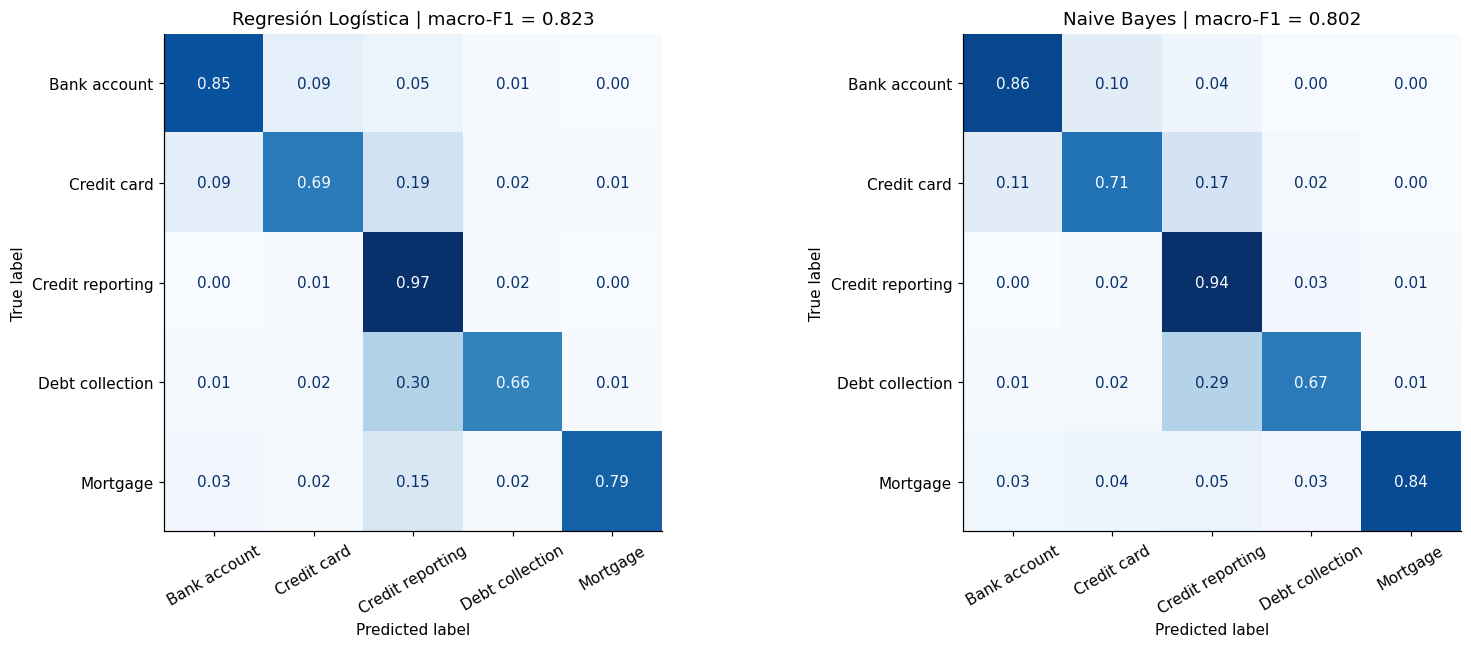

,f1_macro,accuracy,log_loss
Regresión Logística,0.8233,0.9073,0.2730
Naive Bayes,0.8023,0.8893,0.3584


Mayor confusión (LR): Debt collection → Credit reporting (30.1% de los casos de Debt collection)


In [37]:
# ===== Evaluación en test =====
final = {"Regresión Logística": best_lr.fit(X_train, y_train), "Naive Bayes": best_nb.fit(X_train, y_train)}
test_scores = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, m) in zip(axes, final.items()):
    pred = m.predict(X_test)
    test_scores[name] = dict(f1_macro=f1_score(y_test, pred, average="macro"),
                             accuracy=(pred == y_test).mean(), log_loss=log_loss(y_test, m.predict_proba(X_test)))
    print(f"===== {name} =====\n", classification_report(y_test, pred, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, normalize="true", ax=ax, cmap="Blues",
                                            values_format=".2f", colorbar=False, xticks_rotation=30)
    ax.set_title(f"{name} | macro-F1 = {test_scores[name]['f1_macro']:.3f}")
plt.tight_layout(); plt.show()
display(pd.DataFrame(test_scores).T.round(4))

cm = confusion_matrix(y_test, final["Regresión Logística"].predict(X_test), labels=classes, normalize="true")
np.fill_diagonal(cm, 0); i, j = np.unravel_index(cm.argmax(), cm.shape)
most_confused = (classes[i], classes[j], cm[i, j])
print(f"Mayor confusión (LR): {classes[i]} → {classes[j]} ({cm[i, j]:.1%} de los casos de {classes[i]})")

El siguiente código muestra, para la Regresión Logística, los 12 términos TF‑IDF con mayor coeficiente en cada clase. Estos términos son los que más empujan la predicción hacia esa clase, lo que hace al modelo **interpretable**.

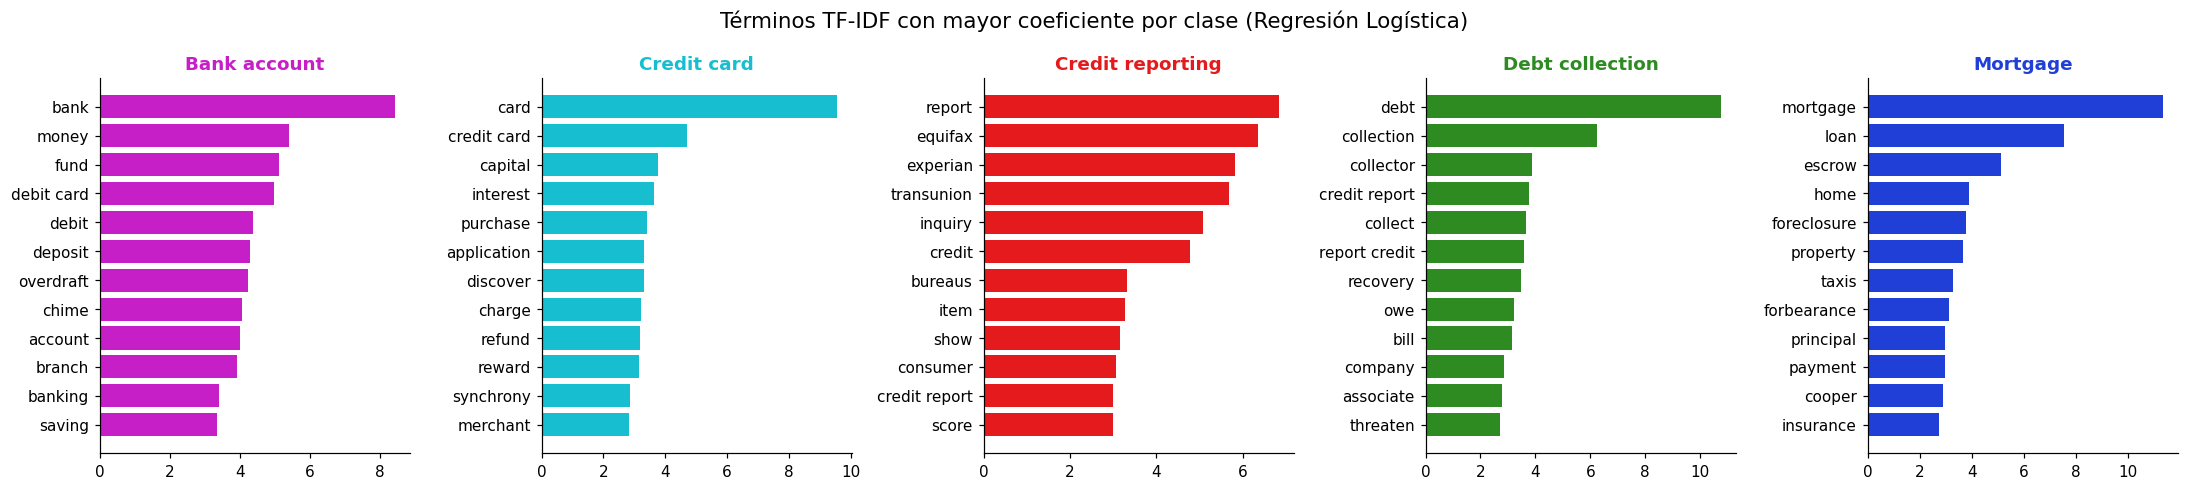

In [38]:
# ===== Interpretabilidad: términos con mayor peso por clase =====
lr_m = final["Regresión Logística"]
feat = lr_m.named_steps["tfidf"].get_feature_names_out()
coef = lr_m.named_steps["clf"].coef_
fig, axes = plt.subplots(1, len(classes), figsize=(4 * len(classes), 4.5))
for ax, k, c in zip(axes, range(len(classes)), lr_m.named_steps["clf"].classes_):
    top = np.argsort(coef[k])[-12:]
    ax.barh(feat[top], coef[k][top], color=CLASS_COLORS[c]); ax.set_title(c, color=CLASS_COLORS[c], fontweight="bold")
plt.suptitle("Términos TF-IDF con mayor coeficiente por clase (Regresión Logística)", fontsize=14)
plt.tight_layout(); plt.show()

### 📝 Discusión: evaluación en test

* La diagonal de cada matriz de confusión es el *recall* por clase; los valores fuera de la diagonal muestran hacia qué producto se desvían los errores. La mayor confusión impresa debería coincidir con lo anticipado en el EDA (productos que comparten vocabulario).
* Los términos con mayor coeficiente por clase confirman que el modelo aprende vocabulario propio de cada producto (similar al de las nubes de palabras de la sección 4.1), lo que permite explicar sus decisiones a un analista.
* Las métricas en test deben ser parecidas a las de la validación cruzada; si lo son, el modelo no está sobreajustado al proceso de selección de hiperparámetros.

## ✅ 10. Visualización con t‑SNE <a id='10'></a>

TF‑IDF produce vectores de decenas de miles de dimensiones y muy dispersos. Siguiendo la recomendación de van der Maaten & Hinton [12], se reduce primero a 50 componentes con **Truncated SVD** (LSA, equivalente a PCA para matrices dispersas) y luego se aplica **t‑SNE** a 2D sobre el conjunto de test. El color representa el *label* real; los puntos con ✕ son errores de la Regresión Logística. Los recuadros muestran ejemplos reales de quejas en distintas zonas del mapa (análogo a las imágenes del ejemplo del curso).

> **t‑SNE se aplica después del modelo y solo para visualizar.** No se usa como entrada de los clasificadores porque: (1) no tiene `transform` para datos nuevos (habría que recalcular el mapa completo con cada queja), (2) preserva vecindarios locales pero distorsiona las distancias globales, y (3) ajustarlo con todos los datos antes del *split* filtraría información del test. Por eso se calcula con el TF‑IDF ya entrenado (solo con train) sobre el conjunto de test.

El siguiente código:

1. Toma hasta 700 quejas de test por clase y las transforma con el TF‑IDF del modelo final.
2. Reduce a 50 dimensiones con SVD y luego a 2D con t‑SNE; calcula el *silhouette* del mapa por *label*.
3. Dibuja los puntos por clase, marca los errores de la LR y agrega recuadros con un ejemplo típico de cada clase (el punto más cercano al centroide) y un error de clasificación.

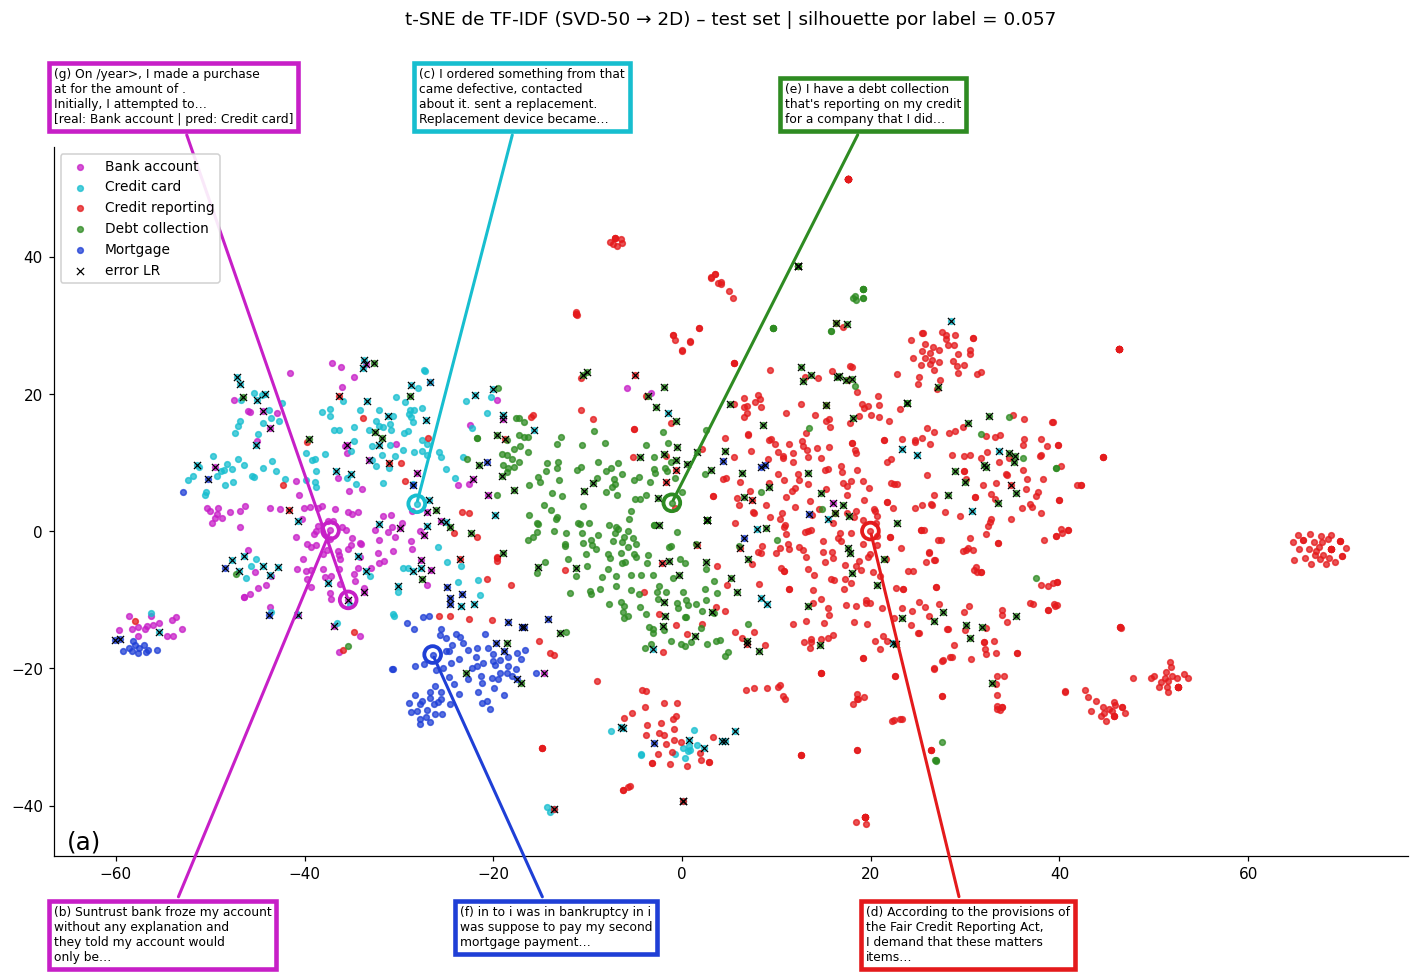

In [39]:
# ===== t-SNE sobre el conjunto de test =====
idx = np.concatenate([rng.choice(np.where(y_test == c)[0], size=min(700, (y_test == c).sum()), replace=False)
                      for c in classes])
Xt_sub = lr_m.named_steps["tfidf"].transform(X_test[idx])
Z50 = TruncatedSVD(n_components=50, random_state=SEED).fit_transform(Xt_sub)
Z = TSNE(n_components=2, perplexity=35, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Z50)
y_sub = y_test[idx]; pred_sub = lr_m.predict(X_test[idx])
raw_sub = df["text"].to_numpy(dtype=object)[idx_test[idx]]
sil = silhouette_score(Z, y_sub)

fig, ax = plt.subplots(figsize=(13, 9))
for c in classes:
    m = y_sub == c
    ax.scatter(Z[m, 0], Z[m, 1], s=14, color=CLASS_COLORS[c], label=c, alpha=.75)
err = y_sub != pred_sub
ax.scatter(Z[err, 0], Z[err, 1], s=22, marker="x", color="k", lw=.8, label="error LR")
ax.legend(loc="upper left", fontsize=9, framealpha=.9)

def snippet(t, n=16):
    t = re.sub(r"\bX{2,}(/X{2,})*\b|\{\$[\d,\.]+\}", "", str(t))
    return textwrap.fill(" ".join(t.split()[:n]) + "…", 30)

# un ejemplo típico por clase (punto más cercano al centroide) + un error de clasificación
boxes = []
for c in classes:
    m = np.where(y_sub == c)[0]; cen = Z[m].mean(0)
    boxes.append((m[np.argmin(((Z[m] - cen) ** 2).sum(1))], c, ""))
if err.any():
    e = np.where(err)[0][0]; boxes.append((e, y_sub[e], f"\n[real: {y_sub[e]} | pred: {pred_sub[e]}]"))
# ubica cada recuadro en la posición libre (alrededor del gráfico) más cercana a su punto
cands = [(x, 1.03) for x in (0.0, 0.27, 0.54, 0.81)] + [(1.02, y) for y in (0.95, 0.62, 0.30)] + \
        [(x, -0.07) for x in (0.0, 0.30, 0.60)]
(x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
taken, placed = set(), []
for k, c, extra in boxes:
    fx, fy = (Z[k, 0] - x0) / (x1 - x0), (Z[k, 1] - y0) / (y1 - y0)
    j = min((j for j in range(len(cands)) if j not in taken),
            key=lambda j: (cands[j][0] + 0.1 - fx) ** 2 + (cands[j][1] - fy) ** 2)
    taken.add(j); placed.append((k, c, extra, cands[j]))
for (k, c, extra, (px, py)), letter in zip(placed, "bcdefgh"):
    ax.annotate(f"({letter}) {snippet(raw_sub[k])}{extra}", xy=Z[k], xytext=(px, py), textcoords="axes fraction",
                fontsize=8, va="bottom" if py > 1 else "top" if py < 0 else "center",
                bbox=dict(boxstyle="square,pad=0.4", fc="white", ec=CLASS_COLORS[c], lw=3),
                arrowprops=dict(arrowstyle="-", color=CLASS_COLORS[c], lw=2))
    ax.scatter(*Z[k], s=120, facecolors="none", edgecolors=CLASS_COLORS[c], lw=2.5)
ax.text(0.01, 0.01, "(a)", transform=ax.transAxes, fontsize=16)
ax.set_title(f"t-SNE de TF-IDF (SVD-50 → 2D) – test set | silhouette por label = {sil:.3f}", pad=80)
plt.tight_layout(); plt.show()

### 📝 Discusión: t‑SNE

Cada producto forma una o varias regiones densas (por ejemplo, *Mortgage* suele aparecer como un grupo compacto y bien separado por su vocabulario específico). Las zonas de solapamiento coinciden con la mayor confusión de la matriz de confusión, y los errores (✕) se concentran en las **fronteras** entre clases o dentro de un grupo ajeno (quejas que en realidad mencionan varios productos). El *silhouette* calculado sobre el embedding cuantifica qué tan separadas quedan las clases (t‑SNE preserva vecindarios locales, no distancias globales, así que se interpreta solo de forma cualitativa [12]).

# ✅ 11. Conclusiones <a id='11'></a>

Las conclusiones se generan a partir de los resultados obtenidos en este notebook (no de la teoría), de modo que se mantienen correctas si se re‑ejecuta con otra muestra.

In [40]:
# ===== Conclusiones a partir de los resultados =====
from IPython.display import Markdown
lr_t, nb_t = test_scores["Regresión Logística"], test_scores["Naive Bayes"]
r_small = r.iloc[0]
signif = p_wil < 0.05 and p_corr < 0.05
if not RUN_OPTUNA:
    optuna_txt = ""
elif hp_source == "Optuna":
    optuna_txt = (f" Optuna redujo la CV log‑loss de {-gs_lr.best_score_:.3f} a {study.best_value:.3f} "
                  "ajustando también el TF‑IDF, por lo que se adoptaron sus hiperparámetros.")
else:
    optuna_txt = " Optuna no mejoró la CV log‑loss del grid, por lo que se mantuvieron los hiperparámetros del grid."
txt = f"""
1. **Datos.** De {len(df):,} quejas con narrativa (2019‑2024), la clase **{counts.idxmax()}** concentra el {pct.max():.1%} y **{counts.idxmin()}** solo el {pct.min():.1%} (ratio {imb_ratio:.1f}:1). Este desbalance justificó usar *stratified* k‑fold y macro‑F1 como métrica principal{f"; la exactitud ({lr_t['accuracy']:.3f} en LR) sobreestima el desempeño por clase (macro‑F1 = {lr_t['f1_macro']:.3f})" if lr_t['accuracy'] - lr_t['f1_macro'] > 0.01 else f" (en LR, exactitud = {lr_t['accuracy']:.3f} y macro‑F1 = {lr_t['f1_macro']:.3f}, por lo que las clases minoritarias se clasifican casi tan bien como la mayoritaria)"}.
2. **Serie temporal.** La fuerza estacional es F_s = {F_s:.2f} ({'débil' if F_s < 0.4 else 'moderada' if F_s < 0.64 else 'fuerte'}) y la fuerza de tendencia F_t = {F_t:.2f} ({'débil' if F_t < 0.4 else 'moderada' if F_t < 0.64 else 'fuerte'}). {'La variación del volumen se explica más por la tendencia que por un patrón anual.' if F_t > F_s else 'El patrón anual pesa más que la tendencia de largo plazo.'} Además la proporción de productos cambia en el tiempo, por lo que un modelo en producción debería re‑entrenarse periódicamente.
3. **Asimetría.** La longitud de las quejas tiene skew = {sk_raw:.2f} (→ {sk_log:.2f} con log1p); usar `sublinear_tf` y normalización L2 dentro del TF‑IDF fue necesario para que la longitud no domine la representación.
4. **Regularización e hiperparámetros.** Con el λ más pequeño probado ({r_small['lambda']:.0e}) la *training loss* fue {-r_small['mean_train_logloss']:.3f} frente a una *CV loss* de {-r_small['mean_test_logloss']:.3f} (brecha = sobreajuste). El λ óptimo del grid fue **{best_lambda:.3g}** (C = {1/best_lambda:.3g}), con CV log‑loss = {-gs_lr.best_score_:.3f} y macro‑F1 = {r.loc[r['lambda']==best_lambda,'mean_test_f1'].item():.3f}; con el λ más grande la CV loss sube a {-r.iloc[-1]['mean_test_logloss']:.3f} (subajuste).{' ⚠️ El óptimo de λ quedó en el borde de la grilla aun después de ampliarla.' if lr_at_edge else ''} Para NB el α óptimo del grid fue {best_alpha:.3g}.{' ⚠️ El óptimo de α quedó en el borde de la grilla aun después de ampliarla.' if nb_at_edge else ''}{optuna_txt} Los modelos finales usan **λ = {final_lambda:.3g}** (LR) y **α = {final_alpha:.3g}** (NB) con el mismo TF‑IDF ({tfidf_txt}).
5. **Curva de aprendizaje.** Para LR el gap final entre CV y training loss es {lc_lr['gap']:.3f} (diagnóstico: *{lc_lr['diag']}*); la CV loss bajó de {lc_lr['cv'][0]:.3f} a {lc_lr['cv'][-1]:.3f} al pasar de {lc_lr['sizes'][0]:,} a {lc_lr['sizes'][-1]:,} ejemplos, {'y sigue descendiendo, por lo que más datos aún aportarían' if lc_lr['cv'][-2]-lc_lr['cv'][-1] > 0.005 else 'y ya está prácticamente estabilizada; más datos aportarían poco'}. {'La CV loss alcanza el objetivo de negocio (' + str(DESIRED_LOSS) + ').' if lc_lr['cv'][-1] <= DESIRED_LOSS else 'La CV loss aún no alcanza el objetivo de negocio (' + str(DESIRED_LOSS) + ').'}
6. **Comparación estadística.** En {len(d)} folds pareados ({CV_CMP.n_repeats}×{n_splits}), LR obtuvo macro‑F1 = {a.mean():.4f} y NB = {b.mean():.4f} (diferencia media {d.mean():+.4f}; LR gana en {wins}/{len(d)} folds). Wilcoxon p = {p_wil:.2e} y t‑test corregido p = {p_corr:.2e}: {'**se rechaza H₀**, la diferencia es estadísticamente significativa a favor de ' + winner if signif else '**no hay evidencia suficiente** (con ambas pruebas) para afirmar que un modelo sea mejor' if (p_wil >= 0.05 and p_corr >= 0.05) else '**las pruebas discrepan** (Wilcoxon p = ' + f'{p_wil:.3f}' + ', t corregido p = ' + f'{p_corr:.3f}' + '); con el criterio conservador del t corregido no se puede afirmar una diferencia robusta'}. El t‑test clásico (p = {p_naive:.2e}) es más optimista que el corregido, como se espera por el solapamiento de folds.
7. **Test.** En el conjunto de test, LR logra macro‑F1 = {lr_t['f1_macro']:.3f} y log‑loss = {lr_t['log_loss']:.3f}, frente a NB con macro‑F1 = {nb_t['f1_macro']:.3f} y log‑loss = {nb_t['log_loss']:.3f}. La mayor confusión es **{most_confused[0]} → {most_confused[1]}** ({most_confused[2]:.1%}), consistente con las zonas de solapamiento en t‑SNE (silhouette = {sil:.3f}).
8. **Recomendación práctica.** {('Se recomienda **' + winner + '** (significativamente mejor en la validación cruzada)') if signif else ('Como la diferencia no es concluyente, se recomienda **' + min(test_scores, key=lambda k: test_scores[k]['log_loss']) + '** por tener mejores probabilidades (menor log‑loss en test), útiles para fijar umbrales de revisión')} con TF‑IDF: entrena en segundos y es interpretable (términos por clase). Las quejas en la frontera {most_confused[0]}/{most_confused[1]} con probabilidad máxima baja deberían derivarse a revisión humana.
"""
display(Markdown(txt))


1. **Datos.** De 14,996 quejas con narrativa (2019‑2024), la clase **Credit reporting** concentra el 73.3% y **Mortgage** solo el 3.8% (ratio 19.1:1). Este desbalance justificó usar *stratified* k‑fold y macro‑F1 como métrica principal; la exactitud (0.907 en LR) sobreestima el desempeño por clase (macro‑F1 = 0.823).
2. **Serie temporal.** La fuerza estacional es F_s = 0.39 (débil) y la fuerza de tendencia F_t = 0.97 (fuerte). La variación del volumen se explica más por la tendencia que por un patrón anual. Además la proporción de productos cambia en el tiempo, por lo que un modelo en producción debería re‑entrenarse periódicamente.
3. **Asimetría.** La longitud de las quejas tiene skew = 7.24 (→ -0.08 con log1p); usar `sublinear_tf` y normalización L2 dentro del TF‑IDF fue necesario para que la longitud no domine la representación.
4. **Regularización e hiperparámetros.** Con el λ más pequeño probado (1e-03) la *training loss* fue 0.013 frente a una *CV loss* de 0.507 (brecha = sobreajuste). El λ óptimo del grid fue **0.1** (C = 10), con CV log‑loss = 0.296 y macro‑F1 = 0.825; con el λ más grande la CV loss sube a 0.828 (subajuste). Para NB el α óptimo del grid fue 0.316. Optuna redujo la CV log‑loss de 0.296 a 0.296 ajustando también el TF‑IDF, por lo que se adoptaron sus hiperparámetros. Los modelos finales usan **λ = 0.146** (LR) y **α = 0.316** (NB) con el mismo TF‑IDF (min_df=6, ngram_range=(1, 2), sublinear_tf=True).
5. **Curva de aprendizaje.** Para LR el gap final entre CV y training loss es 0.204 (diagnóstico: *Good fit*); la CV loss bajó de 0.435 a 0.296 al pasar de 767 a 9,596 ejemplos, y sigue descendiendo, por lo que más datos aún aportarían. La CV loss alcanza el objetivo de negocio (0.3).
6. **Comparación estadística.** En 100 folds pareados (10×10), LR obtuvo macro‑F1 = 0.8257 y NB = 0.8057 (diferencia media +0.0201; LR gana en 92/100 folds). Wilcoxon p = 1.96e-16 y t‑test corregido p = 1.73e-04: **se rechaza H₀**, la diferencia es estadísticamente significativa a favor de Regresión Logística. El t‑test clásico (p = 2.37e-24) es más optimista que el corregido, como se espera por el solapamiento de folds.
7. **Test.** En el conjunto de test, LR logra macro‑F1 = 0.823 y log‑loss = 0.273, frente a NB con macro‑F1 = 0.802 y log‑loss = 0.358. La mayor confusión es **Debt collection → Credit reporting** (30.1%), consistente con las zonas de solapamiento en t‑SNE (silhouette = 0.057).
8. **Recomendación práctica.** Se recomienda **Regresión Logística** (significativamente mejor en la validación cruzada) con TF‑IDF: entrena en segundos y es interpretable (términos por clase). Las quejas en la frontera Debt collection/Credit reporting con probabilidad máxima baja deberían derivarse a revisión humana.


## 12. Referencias (formato IEEE) <a id='12'></a>

[1] Consumer Financial Protection Bureau, "Consumer Complaint Database," 2025. [Online]. Available: https://www.consumerfinance.gov/data-research/consumer-complaints/

[2] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[3] G. Salton and C. Buckley, "Term-weighting approaches in automatic text retrieval," *Inf. Process. Manage.*, vol. 24, no. 5, pp. 513–523, 1988.

[4] C. D. Manning, P. Raghavan, and H. Schütze, *Introduction to Information Retrieval*. Cambridge, U.K.: Cambridge Univ. Press, 2008.

[5] A. McCallum and K. Nigam, "A comparison of event models for naive Bayes text classification," in *Proc. AAAI-98 Workshop Learn. Text Categorization*, 1998, pp. 41–48.

[6] T. Hastie, R. Tibshirani, and J. Friedman, *The Elements of Statistical Learning*, 2nd ed. New York, NY, USA: Springer, 2009.

[7] A. Y. Ng, "Regularization" y "Logistic Regression," material del curso *Aprendizaje Supervisado*, 2024 (figuras de referencia para la curva de λ y la curva de aprendizaje).

[8] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bull.*, vol. 1, no. 6, pp. 80–83, 1945.

[9] C. Nadeau and Y. Bengio, "Inference for the generalization error," *Mach. Learn.*, vol. 52, no. 3, pp. 239–281, 2003.

[10] R. R. Bouckaert and E. Frank, "Evaluating the replicability of significance tests for comparing learning algorithms," in *Proc. PAKDD*, LNCS 3056, 2004, pp. 3–12.

[11] J. Demšar, "Statistical comparisons of classifiers over multiple data sets," *J. Mach. Learn. Res.*, vol. 7, pp. 1–30, 2006.

[12] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.

[13] M. Honnibal, I. Montani, S. Van Landeghem, and A. Boyd, "spaCy: Industrial-strength natural language processing in Python," 2020, doi: 10.5281/zenodo.1212303.

[14] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, "Optuna: A next-generation hyperparameter optimization framework," in *Proc. 25th ACM SIGKDD*, 2019, pp. 2623–2631.

[15] S. Seabold and J. Perktold, "Statsmodels: Econometric and statistical modeling with Python," in *Proc. 9th Python Sci. Conf.*, 2010, pp. 92–96.

[16] R. J. Hyndman and G. Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed. Melbourne, Australia: OTexts, 2021. [Online]. Available: https://otexts.com/fpp3/

[17] A. Mueller, "WordCloud for Python," GitHub repository. [Online]. Available: https://github.com/amueller/word_cloud

[18] J. D. Hunter, "Matplotlib: A 2D graphics environment," *Comput. Sci. Eng.*, vol. 9, no. 3, pp. 90–95, 2007.

[19] P. Virtanen *et al.*, "SciPy 1.0: Fundamental algorithms for scientific computing in Python," *Nature Methods*, vol. 17, pp. 261–272, 2020.

[20] W. McKinney, "Data structures for statistical computing in Python," in *Proc. 9th Python Sci. Conf.*, 2010, pp. 56–61.

[21] scikit-learn developers, "Plotting learning curves and checking models' scalability," scikit-learn documentation. [Online]. Available: https://scikit-learn.org/stable/auto_examples/model_selection/plot_learning_curve.html

[22] scikit-learn developers, "Pipelines and composite estimators," scikit-learn User Guide. [Online]. Available: https://scikit-learn.org/stable/modules/compose.html

[23] scikit-learn developers, "Statistical comparison of models using grid search," scikit-learn documentation. [Online]. Available: https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_stats.html

[24] G. K. Zipf, *Human Behavior and the Principle of Least Effort*. Cambridge, MA, USA: Addison-Wesley, 1949.

[25] Internet Archive, "Wayback Machine: snapshot of files.consumerfinance.gov/ccdb/complaints.csv.zip (31 May 2025)." [Online]. Available: https://web.archive.org/web/20250531184504/https://files.consumerfinance.gov/ccdb/complaints.csv.zip

## Anexo: proceso de desarrollo y prompts utilizados

En este anexo documento cómo desarrollé el proyecto: las decisiones que tomé, lo que ejecuté y revisé, y los *prompts* que usé con un asistente de IA generativa para generar código, corregir errores y agregar funcionalidades.

### A.1 Mi trabajo y mis decisiones

* **Tema, modelos y entorno.** Pedí tres propuestas de proyecto a partir del enunciado del curso, elegí la clasificación de quejas financieras de la CFPB y decidí comparar **Regresión Logística vs Naive Bayes Multinomial** en **Google Colab**.
* **Requisitos y estilo.** Trasladé los requisitos del enunciado a los prompts y aporté las gráficas de referencia de clase (curva de regularización λ y *learning curve*) como guía para replicar sus colores y anotaciones.
* **Formato.** Revisé los laboratorios realizados en clase para que el notebook siguiera el mismo formato: librerías explicadas, markdown antes de cada celda de código y discusión después de cada resultado.
* **Ejecución y pruebas.** Ejecuté el notebook completo en Google Colab desde VS Code con el dataset real (15 000 quejas, comparación 10×10), revisé las salidas y gráficos de cada sección y detecté los problemas que se resolvieron en las iteraciones de A.3.
* **Revisión de resultados.** Verifiqué que los hiperparámetros elegidos se usaran en los modelos finales, que t‑SNE no se aplicara antes del modelo.


### A.2 Prompts por sección (construcción del notebook)

| Sección | Prompt (o fragmento) que originó el código |
|---|---|
| 0. Configuración | "Arma el notebook completo para Google Colab del proyecto de clasificación de quejas CFPB con pipeline Texto -> TF-IDF -> ML, comparando Regresión Logística vs Naive Bayes" |
| 2. Obtención de datos | "Descarga el CFPB Consumer Complaint Database, filtra 5-6 productos y toma una muestra de unas 20-30 mil quejas" (ajustado a 15k por costo computacional del 10x10 CV) |
| 3.1 Balance | "EDA: ¿Es su data balanceada?" |
| 3.2 Skewness | "EDA: ¿Necesito hacer transformaciones no lineales (skewness)?" |
| 3.3 Normalización | "EDA: ¿está normalizada?" (en texto: normas de los vectores BoW vs TF-IDF) |
| 3.4 Estacionalidad | "EDA: ¿hay estacionalidad en series de tiempo? Grafica quejas por mes y descompón la serie" |
| 4. Preprocesamiento | "Si el dominio es texto, después del preprocesamiento de lemmatization and stop words removal" |
| 4.1 Word cloud | "Si el dominio es texto: Word cloud y palabras frecuentes" |
| 5. Pipelines | "Usar pipelines de sklearn: Text -> Bag of words TF-IDF -> ML algorithm" |
| 6. Optimización de λ | "Optimizar sus hiperparámetros en un conjunto de validación adecuado con repeated k-fold cv"; "Se debe generar dos gráficas como las cargadas en este prompt donde se visualice la optimización de lambda de la parte de training y la parte de validación con los colores que se muestran" |
| 6.1 α de Naive Bayes | "Optimizar hiperparámetros con repeated k-fold cv" (modelo 2: Naive Bayes) |
| 6.2 Optuna | "Opcional (extra): usar optuna https://optuna.org" |
| 7. Curva de aprendizaje | "Presentar también la curva de aprendizaje ... con el cv loss versus el training loss y el gap entre ambos, de preferencia mantener los colores del ejemplo" |
| 8. Comparación | "Se debe realizar una comparación estadística entre dos técnicas de aprendizaje automático mediante un test de hipótesis apropiado (Wilcoxon o t-test) utilizando repeated k-fold cross-validation, 10 repeticiones con 10 folds" |
| 9. Evaluación en test | "Evalúa ambos modelos finales en el test set con reporte de clasificación y matriz de confusión"; "Muestra los términos con mayor peso por clase en la Regresión Logística (interpretabilidad)" |
| 10. t-SNE | "Es requerido tener una visualización con TSNE; el color representa el label, verificar el gráfico de ejemplo" |
| 11. Conclusiones | "Finalmente se requiere redactar conclusiones pertinentes. Recordar que la teoría no es una conclusión" |

### A.3 Iteraciones: problemas que encontré y arreglos aplicados

Después de la primera versión, ejecuté y revisé el notebook. Estos son los problemas que encontré o las mejoras que pedí, en orden, y el arreglo que se aplicó en cada caso:

| # | Lo que pedí (prompt o fragmento) | Problema o motivo | Arreglo aplicado (sección) |
|---|---|---|---|
| 1 | "En la ejecución de la parte 2, obtención de datos, me da este error: `ValueError: Usecols do not match columns, columns expected but not found: ['Consumer complaint narrative']`" | La CFPB eliminó en 2026 las narrativas de su descarga oficial y de su API; sin texto no existe el problema de clasificación. | El dataset se descarga desde la copia del archivo oficial del 31‑may‑2025 en Internet Archive [25]; `has_narrative()` verifica que el ZIP tenga narrativas y `download()` hace una descarga reanudable (sección 2). |
| 2 | "¿El ipynb descarga el dataset? ¿Es reproducible por sí solo si lo revisa el profesor?" | El archivo oficial cambiaba a diario, por lo que cada ejecución obtenía una muestra distinta. | Al usar un snapshot fijo, cualquier persona que ejecute el notebook obtiene la misma muestra (sección 2). |
| 3 | "Verifica que el mejor hiperparámetro encontrado sea utilizado para el mejoramiento, también revisa si se aplica t‑SNE antes del modelo" |  Optuna encontraba mejores hiperparámetros pero no se usaban, y el óptimo podía quedar en el borde de la grilla. | Nueva sección 6.3 que elige los hiperparámetros finales (grid vs Optuna) y vuelve a ajustar α sobre el mismo TF‑IDF; `search_with_widening()` amplía la grilla si el óptimo cae en un extremo (sección 6). Nota en la sección 10: t‑SNE se aplica solo después del modelo, para visualizar. |
| 4 | "La descarga del dataset se tarda mucho, ¿podemos hacer que en la primera corrida se descargue una sola vez en una carpeta llamada dataset y de ahí en adelante tome de esa carpeta?" | ~25 min de descarga en cada sesión. Además, el caché ignoraba `N_SAMPLE` y el generador aleatorio cambiaba el t‑SNE entre la primera corrida y las siguientes. | Carpeta `dataset` (en Google Drive cuando se ejecuta en Colab) que guarda el ZIP y los `parquet`; nombres de archivo con `N_SAMPLE` y `KEEP_FRAC`; generador aleatorio propio para la carga, de modo que los resultados son idénticos con o sin caché (secciones 0 y 2). |

Todo el código generado o corregido con ayuda de IA lo ejecuté en Google Colab con el dataset real y revisé sus resultados antes de incluirlo en la entrega.